# Credit Card Fraud Detection

**An end-to-end machine learning project for identifying potentially fraudulent credit card transactions.**

This project explores an extremely imbalanced transaction dataset, investigates patterns in legitimate and fraudulent transactions, compares multiple machine learning approaches, and evaluates a final XGBoost classifier on an independent test set.

## Project objectives

- Inspect and clean the transaction dataset.
- Explore class imbalance and relationships between features and the fraud label.
- Prepare the data using stratified splitting and appropriate feature scaling.
- Compare class-weighting and SMOTE as approaches to class imbalance.
- Train and evaluate multiple classification algorithms.
- Optimize a classification threshold using validation data.
- Evaluate the selected model once on a separate final test set.

## Dataset at a glance

| Property | Description |
|---|---|
| Dataset | European credit card transactions |
| Original records | 284,807 |
| Features | 30 input features |
| Target | `Class` — 0: legitimate, 1: fraud |
| Fraud records after duplicate removal | 473 |
| Cleaned records | 283,726 |
| Main challenge | Severe class imbalance |

The `V1`–`V28` variables are anonymized PCA-transformed features. `Time` represents elapsed seconds from the first transaction, and `Amount` represents the transaction amount.

## Evaluation approach

Accuracy is reported, but it is not treated as the only measure of success because the dataset is highly imbalanced. Precision, recall, F1-score, ROC-AUC and Average Precision (PR-AUC) are also considered.

**Reproducibility note:** The notebook expects the dataset at `/content/creditcard.csv` when run in Google Colab. The dataset itself is not included in this repository; see `data/README.md` for download and placement instructions.

---

## Notebook workflow

1. Dataset verification
2. Exploratory data analysis
3. Data preprocessing
4. Handling class imbalance
5. Exploratory model building
6. Model evaluation and feature importance
7. Validation-based model selection and threshold optimization
8. Final model training and independent test evaluation
9. Conclusion and limitations


In [4]:
import pandas as pd

file_path = "/content/creditcard.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
# ============================================================
# 1.2 DATASET STRUCTURE AND QUALITY CHECK
# ============================================================

print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

df.info()

print("\n" + "=" * 60)
print("MISSING VALUE ANALYSIS")
print("=" * 60)

print("Total missing values:", df.isnull().sum().sum())

print("\nMissing values by column:")
print(df.isnull().sum())

print("\n" + "=" * 60)
print("DUPLICATE VALUE ANALYSIS")
print("=" * 60)

print("Total duplicate rows:", df.duplicated().sum())

print("\n" + "=" * 60)
print("TARGET VARIABLE DISTRIBUTION")
print("=" * 60)

print(df['Class'].value_counts())

print("\nTarget distribution in percentage:")
print((df['Class'].value_counts(normalize=True) * 100).round(4))

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  flo

In [6]:
# ============================================================
# 1.4 DUPLICATE RECORD INVESTIGATION
# ============================================================

print("=" * 60)
print("DUPLICATE RECORD ANALYSIS")
print("=" * 60)

# Identify duplicate occurrences (excluding the first occurrence)
duplicate_rows = df[df.duplicated()]

print("\nDuplicate rows by class:")
print(duplicate_rows['Class'].value_counts())

print("\nDuplicate rows by class (percentage):")
print(
    (duplicate_rows['Class'].value_counts(normalize=True) * 100)
    .round(4)
)

# Check whether identical feature values have different labels
feature_columns = df.drop(columns=['Class']).columns

feature_duplicates = df[
    df.duplicated(subset=feature_columns, keep=False)
]

print("\n" + "=" * 60)
print("IDENTICAL FEATURES WITH POSSIBLE LABEL CONFLICTS")
print("=" * 60)

print("Rows with repeated feature combinations:",
      len(feature_duplicates))

print("Different labels among repeated feature combinations:")
print(
    feature_duplicates.groupby(list(feature_columns))['Class']
    .nunique()
    .value_counts()
    .sort_index()
)

DUPLICATE RECORD ANALYSIS

Duplicate rows by class:
Class
0    1062
1      19
Name: count, dtype: int64

Duplicate rows by class (percentage):
Class
0    98.2424
1     1.7576
Name: proportion, dtype: float64

IDENTICAL FEATURES WITH POSSIBLE LABEL CONFLICTS
Rows with repeated feature combinations: 1854
Different labels among repeated feature combinations:
Class
1    773
Name: count, dtype: int64


In [7]:
# ============================================================
# 1.6 EXACT DUPLICATE REMOVAL
# ============================================================

# Preserve the original dataset
df_original = df.copy()

# Remove exact duplicate rows
df_clean = df.drop_duplicates().copy()

print("=" * 60)
print("DATA CLEANING SUMMARY")
print("=" * 60)

print("Original dataset shape:", df_original.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("Rows removed:", len(df_original) - len(df_clean))
print("Remaining duplicate rows:", df_clean.duplicated().sum())

print("\nClass distribution after duplicate removal:")
print(df_clean['Class'].value_counts())

print("\nClass distribution percentage:")
print(
    (df_clean['Class'].value_counts(normalize=True) * 100).round(4)
)

DATA CLEANING SUMMARY
Original dataset shape: (284807, 31)
Cleaned dataset shape: (283726, 31)
Rows removed: 1081
Remaining duplicate rows: 0

Class distribution after duplicate removal:
Class
0    283253
1       473
Name: count, dtype: int64

Class distribution percentage:
Class
0    99.8333
1     0.1667
Name: proportion, dtype: float64


### 1.7 Dataset Verification Conclusion

The original dataset contained 284,807 transactions and 31 columns.
The dataset had no missing values but contained 1,081 exact duplicate
records.

After removing exact duplicates, the cleaned dataset contained
283,726 transactions with no remaining exact duplicates.

The target variable showed severe class imbalance:
- Legitimate transactions (Class 0): 283,253
- Fraudulent transactions (Class 1): 473

The fraud class represented approximately 0.1667% of the cleaned
dataset. Therefore, evaluation metrics such as precision, recall,
F1-score, and Precision-Recall AUC will be important alongside
accuracy.

CLASS DISTRIBUTION
Legitimate transactions: 283253
Fraudulent transactions: 473

Class percentages:
Class
0    99.8333
1     0.1667
Name: proportion, dtype: float64


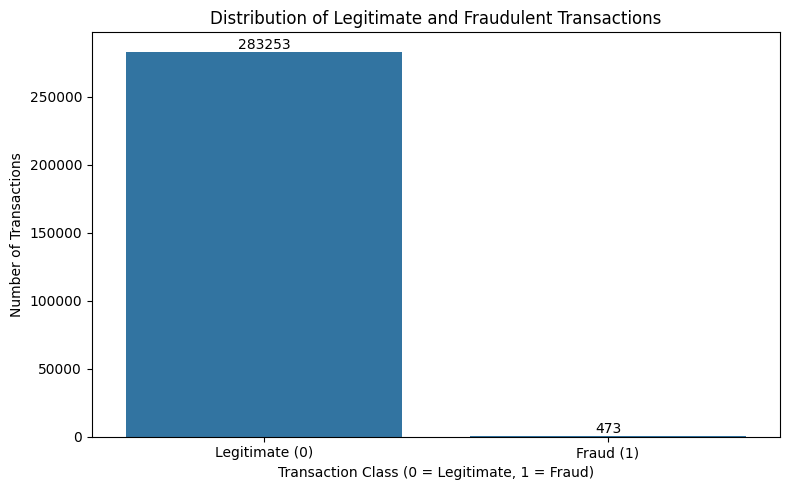

In [8]:
# ============================================================
# 2.1 CLASS DISTRIBUTION ANALYSIS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate class counts
class_counts = df_clean['Class'].value_counts().sort_index()

# Calculate class percentages
class_percentages = (
    df_clean['Class'].value_counts(normalize=True).sort_index() * 100
)

print("=" * 60)
print("CLASS DISTRIBUTION")
print("=" * 60)

print("Legitimate transactions:", class_counts[0])
print("Fraudulent transactions:", class_counts[1])

print("\nClass percentages:")
print(class_percentages.round(4))

# Visualize class distribution
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df_clean,
    x='Class'
)

plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ['Legitimate (0)', 'Fraud (1)'])

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')

plt.tight_layout()
plt.show()

In [10]:
print("\nCLASS DISTRIBUTION INTERPRETATION")

print(f"Legitimate: {class_counts[0]:,} "
      f"({class_percentages[0]:.4f}%)")

print(f"Fraud: {class_counts[1]:,} "
      f"({class_percentages[1]:.4f}%)")

print(f"Imbalance ratio: "
      f"{class_counts[0] / class_counts[1]:.2f}:1")


CLASS DISTRIBUTION INTERPRETATION
Legitimate: 283,253 (99.8333%)
Fraud: 473 (0.1667%)
Imbalance ratio: 598.84:1


### 2.1 Class Distribution — Observation

The dataset is highly imbalanced, with legitimate transactions
representing 99.8333% and fraudulent transactions representing
only 0.1667% of all transactions.

The imbalance ratio is approximately 598.84:1.

This severe class imbalance makes fraud detection challenging.
Therefore, accuracy alone cannot measure model performance
effectively. Precision, recall, F1-score and Precision-Recall
AUC will be considered during model evaluation.

TRANSACTION AMOUNT STATISTICS
        count        mean  median  min       max         std
Class                                                       
0      283253   88.413575   22.00  0.0  25691.16  250.379023
1         473  123.871860    9.82  0.0   2125.87  260.211041


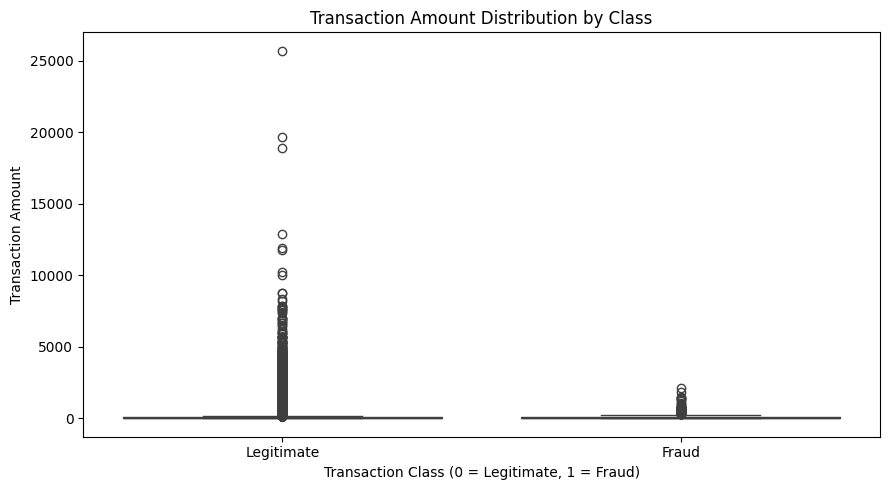

In [9]:
# ============================================================
# 2.2 TRANSACTION AMOUNT ANALYSIS
# ============================================================

print("=" * 60)
print("TRANSACTION AMOUNT STATISTICS")
print("=" * 60)

amount_summary = df_clean.groupby('Class')['Amount'].agg(
    ['count', 'mean', 'median', 'min', 'max', 'std']
)

print(amount_summary)

# Visualize transaction amounts
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x='Class',
    y='Amount'
)

plt.title("Transaction Amount Distribution by Class")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount")
plt.xticks([0, 1], ['Legitimate', 'Fraud'])

plt.tight_layout()
plt.show()

In [11]:
print("\nAMOUNT DISTRIBUTION INTERPRETATION")
print(amount_summary.round(2))


AMOUNT DISTRIBUTION INTERPRETATION
        count    mean  median  min       max     std
Class                                               
0      283253   88.41   22.00  0.0  25691.16  250.38
1         473  123.87    9.82  0.0   2125.87  260.21


### 2.2 Transaction Amount Analysis — Observation

The average transaction amount for fraudulent transactions (123.87)
is higher than that of legitimate transactions (88.41).

However, the median amount for fraudulent transactions (9.82) is
lower than the median for legitimate transactions (22.00).

The substantial difference between mean and median suggests
right-skewness in both distributions, indicating the presence
of high-value transactions.

Therefore, transaction amount alone may not be sufficient to
distinguish fraudulent transactions from legitimate transactions.
It should be analyzed alongside other features.

In [12]:
# ============================================================
# 2.3 TRANSACTION TIME ANALYSIS
# ============================================================

print("=" * 60)
print("TRANSACTION TIME STATISTICS")
print("=" * 60)

time_summary = df_clean.groupby('Class')['Time'].agg(
    ['count', 'mean', 'median', 'min', 'max', 'std']
)

print(time_summary.round(2))

print("\nTRANSACTION TIME INTERPRETATION")
print(time_summary.round(2))

TRANSACTION TIME STATISTICS
        count      mean   median    min       max       std
Class                                                      
0      283253  94835.06  84711.0    0.0  172792.0  47475.55
1         473  80450.51  73408.0  406.0  170348.0  48636.18

TRANSACTION TIME INTERPRETATION
        count      mean   median    min       max       std
Class                                                      
0      283253  94835.06  84711.0    0.0  172792.0  47475.55
1         473  80450.51  73408.0  406.0  170348.0  48636.18


In [13]:
print("\nTIME RANGE COMPARISON")

for class_value, label in [(0, "Legitimate"), (1, "Fraud")]:
    values = df_clean[df_clean['Class'] == class_value]['Time']

    print(f"\n{label}:")
    print(f"25th percentile: {values.quantile(0.25):.2f}")
    print(f"50th percentile: {values.quantile(0.50):.2f}")
    print(f"75th percentile: {values.quantile(0.75):.2f}")


TIME RANGE COMPARISON

Legitimate:
25th percentile: 54233.00
50th percentile: 84711.00
75th percentile: 139308.00

Fraud:
25th percentile: 41203.00
50th percentile: 73408.00
75th percentile: 129095.00


### 2.3 Transaction Time Analysis — Observation

The average transaction time for fraudulent transactions (80,450.51)
is lower than that of legitimate transactions (94,835.06).

The median transaction time is also lower for fraudulent transactions.

Both classes have similar standard deviations, indicating considerable
variation in transaction times.

Although some differences exist between the two classes, their time
ranges overlap substantially. Therefore, the Time feature alone
cannot reliably distinguish fraudulent transactions.

Note: Time represents elapsed seconds from the first transaction
in the dataset, not the actual time of day.

In [14]:
# ============================================================
# 2.4 PCA FEATURE ANALYSIS
# ============================================================

pca_columns = [f'V{i}' for i in range(1, 29)]

# Calculate mean values for each class
pca_means = df_clean.groupby('Class')[pca_columns].mean().T

# Calculate standard deviation for each class
pca_std = df_clean.groupby('Class')[pca_columns].std().T

# Calculate absolute difference between class means
pca_means['Mean Difference'] = (
    pca_means[1] - pca_means[0]
).abs()

print("=" * 60)
print("PCA FEATURE MEAN COMPARISON")
print("=" * 60)

print(pca_means.round(4))

print("\nTOP 10 FEATURES WITH LARGEST MEAN DIFFERENCES")

print(
    pca_means['Mean Difference']
    .sort_values(ascending=False)
    .head(10)
    .round(4)
)

PCA FEATURE MEAN COMPARISON
Class       0       1  Mean Difference
V1     0.0134 -4.4983           4.5117
V2    -0.0098  3.4060           3.4158
V3     0.0129 -6.7296           6.7425
V4    -0.0104  4.4726           4.4830
V5     0.0068 -2.9572           2.9640
V6     0.0013 -1.4325           1.4338
V7     0.0104 -5.1759           5.1864
V8    -0.0024  0.9533           0.9557
V9     0.0026 -2.5221           2.5247
V10    0.0077 -5.4533           5.4609
V11   -0.0060  3.7163           3.7224
V12    0.0095 -6.1033           6.1127
V13    0.0008 -0.0943           0.0951
V14    0.0117 -6.8359           6.8476
V15    0.0012 -0.0728           0.0740
V16    0.0078 -4.0010           4.0088
V17    0.0110 -6.4633           6.4742
V18    0.0051 -2.1571           2.1622
V19   -0.0014  0.6691           0.6705
V20   -0.0005  0.4050           0.4055
V21   -0.0012  0.4666           0.4677
V22   -0.0002  0.0866           0.0868
V23    0.0004 -0.0965           0.0968
V24    0.0004 -0.1066           0.10

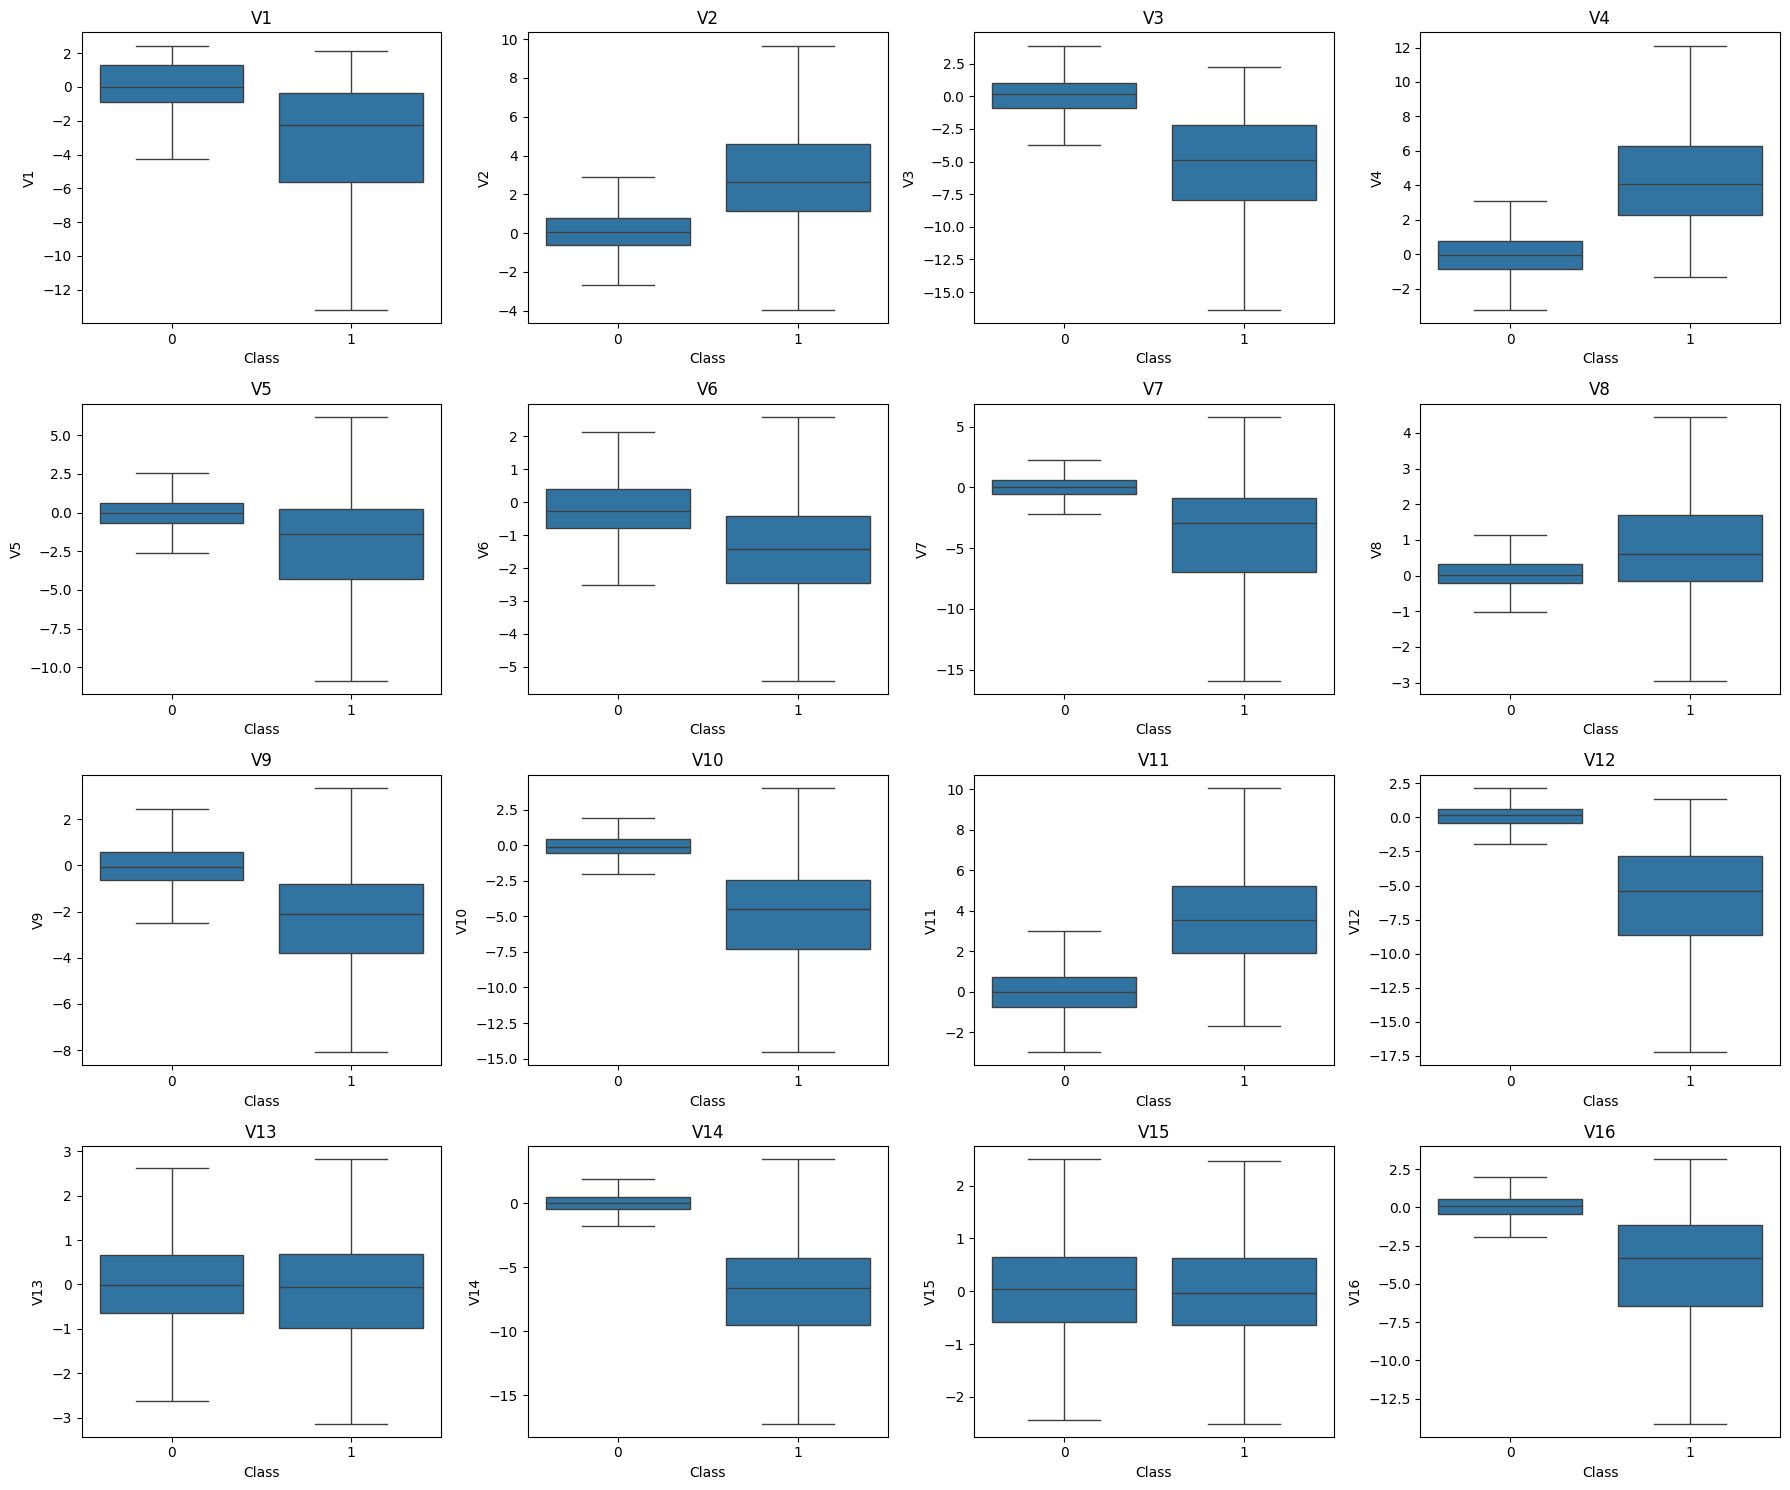

In [15]:
# ============================================================
# 2.4.1 PCA FEATURE DISTRIBUTIONS
# ============================================================

fig, axes = plt.subplots(4, 4, figsize=(18, 15))

for i, ax in enumerate(axes.flat):
    feature = pca_columns[i]

    sns.boxplot(
        data=df_clean,
        x='Class',
        y=feature,
        ax=ax,
        showfliers=False
    )

    ax.set_title(feature)
    ax.set_xlabel('Class')

plt.tight_layout()
plt.show()

### 2.4 PCA Feature Analysis — Observation

The comparison of feature means across legitimate and fraudulent
transactions reveals substantial differences in several PCA features.

The five features with the largest absolute mean differences are:

1. V14: 6.8476
2. V3: 6.7425
3. V17: 6.4742
4. V12: 6.1127
5. V10: 5.4609

These differences suggest that certain PCA-transformed features
may contain useful information for fraud detection.

However, differences in mean values alone do not establish
predictive importance. Further distribution analysis and
model evaluation will be required.

Note: V1–V28 are anonymized PCA-transformed features and do not
directly represent interpretable transaction characteristics.

In [16]:
# ============================================================
# 2.5 FEATURE CORRELATION ANALYSIS
# ============================================================

correlation = df_clean.corr(numeric_only=True)['Class'].drop('Class')

correlation = correlation.sort_values(
    key=abs,
    ascending=False
)

print("=" * 60)
print("TOP 15 FEATURES CORRELATED WITH FRAUD")
print("=" * 60)

print(correlation.head(15).round(4))

TOP 15 FEATURES CORRELATED WITH FRAUD
V17   -0.3135
V14   -0.2934
V12   -0.2507
V10   -0.2070
V16   -0.1872
V3    -0.1823
V7    -0.1723
V11    0.1491
V4     0.1293
V18   -0.1053
V1    -0.0945
V9    -0.0940
V5    -0.0878
V2     0.0846
V6    -0.0439
Name: Class, dtype: float64


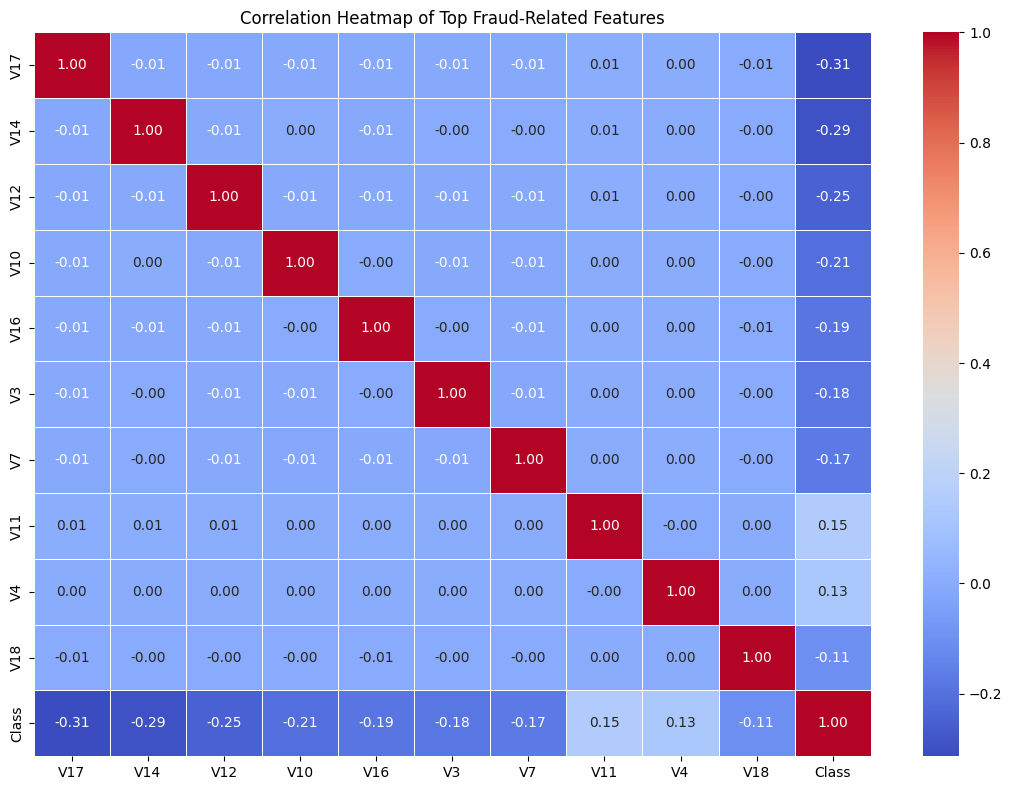

In [17]:
# ============================================================
# 2.5.1 CORRELATION HEATMAP
# ============================================================

top_features = correlation.head(10).index.tolist() + ['Class']

plt.figure(figsize=(11, 8))

sns.heatmap(
    df_clean[top_features].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Top Fraud-Related Features")
plt.tight_layout()
plt.show()

### 2.5 Feature Correlation Analysis — Observation

The correlation analysis identified several PCA features with
relatively stronger linear relationships with the target variable.

The top five features by absolute correlation are:

1. V17: -0.3135
2. V14: -0.2934
3. V12: -0.2507
4. V10: -0.2070
5. V16: -0.1872

Negative correlations indicate an inverse linear association
with the fraud label, while positive correlations indicate
a positive linear association.

The findings are consistent with the earlier PCA mean comparison,
where V14, V17, V12 and V10 also showed substantial differences.

However, correlation alone cannot determine feature importance
or establish causation. All features will initially be retained
for model development.

### 2.6 Exploratory Data Analysis — Overall Conclusion

The exploratory analysis revealed that the dataset is highly
imbalanced, with fraudulent transactions representing only
0.1667% of the cleaned dataset.

Transaction amount and time show differences between the two
classes, but neither feature alone provides sufficient evidence
for reliable fraud detection.

Several PCA-transformed features, particularly V14, V17, V12,
V10 and V3, show noticeable differences between legitimate
and fraudulent transactions.

The correlation analysis further supports the potential
usefulness of these features.

Based on these findings, the next stage will focus on data
preprocessing, appropriate scaling, stratified data splitting
and handling class imbalance.

# 3. Data Preprocessing

The exploratory analysis is followed by feature-target separation, a stratified train-test split, and feature scaling. The scaler is fitted on training data only to avoid leaking information from the test set into preprocessing.

In [18]:
# ============================================================
# 3.1 FEATURE AND TARGET SEPARATION
# ============================================================

X = df_clean.drop(columns=['Class'])
y = df_clean['Class']

print("=" * 60)
print("FEATURE AND TARGET SEPARATION")
print("=" * 60)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

FEATURE AND TARGET SEPARATION
Feature shape: (283726, 30)
Target shape: (283726,)

Feature columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']

Target distribution:
Class
0    283253
1       473
Name: count, dtype: int64


In [19]:
# ============================================================
# 3.2 STRATIFIED TRAIN-TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("=" * 60)
print("TRAIN-TEST SPLIT RESULTS")
print("=" * 60)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

print("\nFraud percentage:")
print("Training:", round(y_train.mean() * 100, 4), "%")
print("Testing:", round(y_test.mean() * 100, 4), "%")

TRAIN-TEST SPLIT RESULTS
Training features: (226980, 30)
Testing features: (56746, 30)

Training target distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Testing target distribution:
Class
0    56651
1       95
Name: count, dtype: int64

Fraud percentage:
Training: 0.1665 %
Testing: 0.1674 %


### 3.2 Train-Test Split — Observation

The cleaned dataset was divided into training and testing
subsets using an 80:20 stratified split.

Training dataset:
- Total transactions: 226,980
- Legitimate: 226,602
- Fraudulent: 378

Testing dataset:
- Total transactions: 56,746
- Legitimate: 56,651
- Fraudulent: 95

Stratification preserved the class distribution across both
subsets, ensuring representative training and testing data.

A random state of 42 was used to make the split reproducible.

In [20]:
# ============================================================
# 3.3 FEATURE SCALING
# ============================================================

from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using training statistics
X_test_scaled = scaler.transform(X_test)

# Convert arrays back to DataFrames
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

print("=" * 60)
print("FEATURE SCALING RESULTS")
print("=" * 60)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("\nTraining feature statistics:")
print(X_train_scaled[['Time', 'Amount']].agg(
    ['mean', 'std']
).round(4))

print("\nTesting feature statistics:")
print(X_test_scaled[['Time', 'Amount']].agg(
    ['mean', 'std']
).round(4))

print("\nMissing values after scaling:")
print("Training:", X_train_scaled.isnull().sum().sum())
print("Testing:", X_test_scaled.isnull().sum().sum())

FEATURE SCALING RESULTS
Training shape: (226980, 30)
Testing shape: (56746, 30)

Training feature statistics:
      Time  Amount
mean  -0.0     0.0
std    1.0     1.0

Testing feature statistics:
        Time  Amount
mean -0.0094  0.0017
std   0.9992  1.0910

Missing values after scaling:
Training: 0
Testing: 0


### 3.3 Feature Scaling — Observation

StandardScaler was applied to the input features.

The scaler was fitted exclusively on the training dataset
and subsequently used to transform the testing dataset.

The training features have approximately zero mean and unit
standard deviation.

The testing dataset was transformed using the same training
statistics, so its mean and standard deviation may differ
slightly from zero and one.

No missing values were introduced during scaling.

This approach prevents data leakage during preprocessing.

# 4. Handling Class Imbalance

Fraudulent transactions form a very small fraction of the dataset. This section examines two approaches: class weighting and Synthetic Minority Over-sampling Technique (SMOTE). Resampling is applied to training data only; validation and test data retain their original class distribution.

In [21]:
# ============================================================
# 4.1 CLASS WEIGHT CALCULATION
# ============================================================

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("=" * 60)
print("CLASS WEIGHTS")
print("=" * 60)

print("Legitimate class weight:", round(class_weights[0], 4))
print("Fraud class weight:", round(class_weights[1], 4))

print("\nClass weight ratio:")
print(round(class_weights[1] / class_weights[0], 2))

CLASS WEIGHTS
Legitimate class weight: 0.5008
Fraud class weight: 300.2381

Class weight ratio:
599.48


### 4.1 Class Weight Calculation — Observation

Balanced class weights were calculated using the training labels.

- Legitimate class weight: 0.5008
- Fraud class weight: 300.2381

The fraud class receives approximately 599.48 times more
weight than the legitimate class.

This approach increases the penalty associated with
misclassifying fraudulent transactions without changing
the original class distribution.

Class weighting will be evaluated as one approach to
handling class imbalance.

In [22]:

!pip install imbalanced-learn -q

In [23]:
from imblearn.over_sampling import SMOTE

In [24]:
# ============================================================
# 4.2 SMOTE OVERSAMPLING
# ============================================================

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("=" * 60)
print("SMOTE RESULTS")
print("=" * 60)

print("\nBefore SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

print("\nBefore SMOTE:", X_train_scaled.shape)
print("After SMOTE:", X_train_smote.shape)

print("\nClass distribution after SMOTE:")
print(y_train_smote.value_counts(normalize=True) * 100)

SMOTE RESULTS

Before SMOTE:
Class
0    226602
1       378
Name: count, dtype: int64

After SMOTE:
Class
0    226602
1    226602
Name: count, dtype: int64

Before SMOTE: (226980, 30)
After SMOTE: (453204, 30)

Class distribution after SMOTE:
Class
0    50.0
1    50.0
Name: proportion, dtype: float64


### 4.2 SMOTE Oversampling — Observation

SMOTE was applied exclusively to the scaled training dataset.

Before oversampling:
- Legitimate transactions: 226,602
- Fraudulent transactions: 378

After oversampling:
- Legitimate transactions: 226,602
- Fraudulent transactions: 226,602
- Total transactions: 453,204

SMOTE generated 226,224 synthetic fraudulent samples,
resulting in a balanced 50:50 class distribution.

The original testing dataset was not modified.

The effectiveness of SMOTE will be evaluated by comparing
model performance against class-weighted and baseline models.

# 5. Exploratory Model Building

Several classifiers are trained and compared using the exploratory split. These experiments help identify promising approaches and understand the precision-recall trade-off. Their results are exploratory because the same test split is used across these comparisons; final performance is assessed later on a separate holdout test set.

In [25]:
# ============================================================
# 5.1 BASELINE LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression

# Initialize model
lr_baseline = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model on original imbalanced training data
lr_baseline.fit(X_train_scaled, y_train)

# Generate predictions
y_pred_baseline = lr_baseline.predict(X_test_scaled)

# Generate fraud probabilities
y_prob_baseline = lr_baseline.predict_proba(X_test_scaled)[:, 1]

print("=" * 60)
print("BASELINE LOGISTIC REGRESSION")
print("=" * 60)

print("Model training completed successfully.")
print("Predictions generated:", len(y_pred_baseline))

BASELINE LOGISTIC REGRESSION
Model training completed successfully.
Predictions generated: 56746


In [26]:
# ============================================================
# 5.1.1 BASELINE MODEL EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("=" * 60)
print("BASELINE MODEL PERFORMANCE")
print("=" * 60)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_baseline), 4
))

print("Precision:", round(
    precision_score(y_test, y_pred_baseline, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_test, y_pred_baseline, zero_division=0), 4
))

print("F1-score:", round(
    f1_score(y_test, y_pred_baseline, zero_division=0), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, y_prob_baseline), 4
))

print("PR-AUC (Average Precision):", round(
    average_precision_score(y_test, y_prob_baseline), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_baseline))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_baseline,
    target_names=['Legitimate', 'Fraud'],
    zero_division=0
))

BASELINE MODEL PERFORMANCE
Accuracy: 0.9991
Precision: 0.8462
Recall: 0.5789
F1-score: 0.6875
ROC-AUC: 0.956
PR-AUC (Average Precision): 0.692

Confusion Matrix:
[[56641    10]
 [   40    55]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.85      0.58      0.69        95

    accuracy                           1.00     56746
   macro avg       0.92      0.79      0.84     56746
weighted avg       1.00      1.00      1.00     56746



### 5.1 Baseline Logistic Regression — Results

Logistic Regression was trained using the original imbalanced
training dataset without class weighting or oversampling.

Performance:
- Accuracy: 0.9991
- Precision: 0.8462
- Recall: 0.5789
- F1-score: 0.6875
- ROC-AUC: 0.9560
- PR-AUC: 0.6920

Confusion Matrix:
[[56641, 10],
 [40, 55]]

The model correctly identified 55 out of 95 fraudulent
transactions while missing 40 fraudulent transactions.

Although the model achieved high precision and ROC-AUC,
its recall indicates that a considerable number of fraud
cases remain undetected.

This model will serve as the baseline for comparison
with class-weighted and SMOTE-based approaches.

In [27]:
# ============================================================
# 5.2 CLASS-WEIGHTED LOGISTIC REGRESSION
# ============================================================

lr_weighted = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

# Train using original imbalanced training data
lr_weighted.fit(X_train_scaled, y_train)

# Generate predictions
y_pred_weighted = lr_weighted.predict(X_test_scaled)

# Generate fraud probabilities
y_prob_weighted = lr_weighted.predict_proba(X_test_scaled)[:, 1]

print("=" * 60)
print("CLASS-WEIGHTED LOGISTIC REGRESSION")
print("=" * 60)

print("Model training completed successfully.")
print("Predictions generated:", len(y_pred_weighted))

CLASS-WEIGHTED LOGISTIC REGRESSION
Model training completed successfully.
Predictions generated: 56746


In [28]:
# ============================================================
# 5.2.1 CLASS-WEIGHTED MODEL EVALUATION
# ============================================================

print("=" * 60)
print("CLASS-WEIGHTED MODEL PERFORMANCE")
print("=" * 60)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_weighted), 4
))

print("Precision:", round(
    precision_score(y_test, y_pred_weighted, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_test, y_pred_weighted, zero_division=0), 4
))

print("F1-score:", round(
    f1_score(y_test, y_pred_weighted, zero_division=0), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, y_prob_weighted), 4
))

print("PR-AUC (Average Precision):", round(
    average_precision_score(y_test, y_prob_weighted), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_weighted))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_weighted,
    target_names=['Legitimate', 'Fraud'],
    zero_division=0
))

CLASS-WEIGHTED MODEL PERFORMANCE
Accuracy: 0.9753
Precision: 0.0564
Recall: 0.8737
F1-score: 0.1059
ROC-AUC: 0.9657
PR-AUC (Average Precision): 0.6719

Confusion Matrix:
[[55262  1389]
 [   12    83]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     56651
       Fraud       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746



### 5.2 Class-Weighted Logistic Regression — Results

Logistic Regression was trained using balanced class weights
to give greater importance to fraudulent transactions.

Performance:
- Accuracy: 0.9753
- Precision: 0.0564
- Recall: 0.8737
- F1-score: 0.1059
- ROC-AUC: 0.9657
- PR-AUC: 0.6719

Confusion Matrix:
[[55262, 1389],
 [12, 83]]

The model detected 83 out of 95 fraudulent transactions,
improving recall from 0.5789 to 0.8737 compared with
the baseline model.

However, the number of false positives increased from
10 to 1,389, resulting in a substantial reduction in precision.

Although ROC-AUC improved, PR-AUC decreased slightly.

Therefore, class weighting improved fraud detection sensitivity
but introduced a considerable false-positive problem.

In [29]:
# ============================================================
# 5.3 SMOTE-BASED LOGISTIC REGRESSION
# ============================================================

lr_smote = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train on SMOTE-balanced training data
lr_smote.fit(X_train_smote, y_train_smote)

# Generate predictions on original test data
y_pred_smote = lr_smote.predict(X_test_scaled)

# Generate fraud probabilities
y_prob_smote = lr_smote.predict_proba(X_test_scaled)[:, 1]

print("=" * 60)
print("SMOTE-BASED LOGISTIC REGRESSION")
print("=" * 60)

print("Model training completed successfully.")
print("Predictions generated:", len(y_pred_smote))

SMOTE-BASED LOGISTIC REGRESSION
Model training completed successfully.
Predictions generated: 56746


In [30]:
# ============================================================
# 5.3.1 SMOTE MODEL EVALUATION
# ============================================================

print("=" * 60)
print("SMOTE LOGISTIC REGRESSION PERFORMANCE")
print("=" * 60)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_smote), 4
))

print("Precision:", round(
    precision_score(y_test, y_pred_smote, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_test, y_pred_smote, zero_division=0), 4
))

print("F1-score:", round(
    f1_score(y_test, y_pred_smote, zero_division=0), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, y_prob_smote), 4
))

print("PR-AUC (Average Precision):", round(
    average_precision_score(y_test, y_prob_smote), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_smote))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_smote,
    target_names=['Legitimate', 'Fraud'],
    zero_division=0
))

SMOTE LOGISTIC REGRESSION PERFORMANCE
Accuracy: 0.9737
Precision: 0.053
Recall: 0.8737
F1-score: 0.1
ROC-AUC: 0.9626
PR-AUC (Average Precision): 0.675

Confusion Matrix:
[[55169  1482]
 [   12    83]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.99     56651
       Fraud       0.05      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.54     56746
weighted avg       1.00      0.97      0.99     56746



### 5.3 SMOTE-Based Logistic Regression — Results

Logistic Regression was trained using the SMOTE-balanced
training dataset containing 226,602 legitimate and
226,602 fraudulent transactions.

Performance:
- Accuracy: 0.9737
- Precision: 0.0530
- Recall: 0.8737
- F1-score: 0.1000
- ROC-AUC: 0.9626
- PR-AUC: 0.6750

Confusion Matrix:
[[55169, 1482],
 [12, 83]]

The model detected 83 out of 95 fraudulent transactions,
achieving a recall of 0.8737.

However, it produced 1,482 false positives and achieved
a precision of only 0.0530.

Compared with class-weighted Logistic Regression,
SMOTE achieved identical recall but slightly lower
precision and F1-score.

Therefore, SMOTE did not provide a meaningful improvement
over class weighting in this experiment.

In [31]:
# ============================================================
# 5.4 RANDOM FOREST CLASSIFIER
# ============================================================

from sklearn.ensemble import RandomForestClassifier

rf_baseline = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

# Train on original imbalanced data
rf_baseline.fit(X_train_scaled, y_train)

# Predictions
y_pred_rf = rf_baseline.predict(X_test_scaled)

# Fraud probabilities
y_prob_rf = rf_baseline.predict_proba(X_test_scaled)[:, 1]

print("=" * 60)
print("RANDOM FOREST TRAINING")
print("=" * 60)

print("Training completed successfully.")
print("Predictions generated:", len(y_pred_rf))

RANDOM FOREST TRAINING
Training completed successfully.
Predictions generated: 56746


In [32]:
# ============================================================
# 5.4.1 RANDOM FOREST EVALUATION
# ============================================================

print("=" * 60)
print("RANDOM FOREST PERFORMANCE")
print("=" * 60)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_rf), 4
))

print("Precision:", round(
    precision_score(y_test, y_pred_rf, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_test, y_pred_rf, zero_division=0), 4
))

print("F1-score:", round(
    f1_score(y_test, y_pred_rf, zero_division=0), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, y_prob_rf), 4
))

print("PR-AUC (Average Precision):", round(
    average_precision_score(y_test, y_prob_rf), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=['Legitimate', 'Fraud'],
    zero_division=0
))

RANDOM FOREST PERFORMANCE
Accuracy: 0.9995
Precision: 0.9722
Recall: 0.7368
F1-score: 0.8383
ROC-AUC: 0.9698
PR-AUC (Average Precision): 0.7875

Confusion Matrix:
[[56649     2]
 [   25    70]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.97      0.74      0.84        95

    accuracy                           1.00     56746
   macro avg       0.99      0.87      0.92     56746
weighted avg       1.00      1.00      1.00     56746



### 5.4.2 Random Forest Conclusion

The Random Forest classifier achieved an accuracy of 99.95%, precision of 97.22%, recall of 73.68%, and F1-score of 83.83%.

The model correctly identified 70 out of 95 fraudulent transactions while producing only 2 false positives.

It achieved a ROC-AUC of 0.9698 and an Average Precision (PR-AUC) of 0.7875.

Compared with the Logistic Regression experiments, Random Forest demonstrated a stronger balance between precision and recall, particularly in reducing false positive predictions.

However, the model still missed 25 fraudulent transactions. Further experiments involving alternative algorithms and threshold optimization will be required before selecting the final model.

In [33]:
# ============================================================
# 5.5 DECISION TREE CLASSIFIER
# ============================================================

from sklearn.tree import DecisionTreeClassifier

dt_baseline = DecisionTreeClassifier(
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight=None,
    random_state=42
)

# Train on original imbalanced training data
dt_baseline.fit(X_train, y_train)

# Predictions
y_pred_dt = dt_baseline.predict(X_test)

# Fraud probabilities
y_prob_dt = dt_baseline.predict_proba(X_test)[:, 1]

print("=" * 60)
print("DECISION TREE TRAINING")
print("=" * 60)

print("Training completed successfully.")
print("Predictions generated:", len(y_pred_dt))

DECISION TREE TRAINING
Training completed successfully.
Predictions generated: 56746


In [34]:
# ============================================================
# 5.5.1 DECISION TREE EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("=" * 60)
print("DECISION TREE PERFORMANCE")
print("=" * 60)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_dt), 4
))

print("Precision:", round(
    precision_score(y_test, y_pred_dt, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_test, y_pred_dt, zero_division=0), 4
))

print("F1-score:", round(
    f1_score(y_test, y_pred_dt, zero_division=0), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, y_prob_dt), 4
))

print("PR-AUC (Average Precision):", round(
    average_precision_score(y_test, y_prob_dt), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=['Legitimate', 'Fraud'],
    zero_division=0
))

DECISION TREE PERFORMANCE
Accuracy: 0.9993
Precision: 0.9028
Recall: 0.6842
F1-score: 0.7784
ROC-AUC: 0.8914
PR-AUC (Average Precision): 0.6908

Confusion Matrix:
[[56644     7]
 [   30    65]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.90      0.68      0.78        95

    accuracy                           1.00     56746
   macro avg       0.95      0.84      0.89     56746
weighted avg       1.00      1.00      1.00     56746



### 5.5.2 Decision Tree Conclusion

The Decision Tree classifier achieved an accuracy of 99.93%, precision of 90.28%, recall of 68.42%, and F1-score of 77.84%.

It correctly identified 65 out of 95 fraudulent transactions, while missing 30 fraud cases and generating 7 false positives.

The model achieved a ROC-AUC of 0.8914 and an Average Precision (PR-AUC) of 0.6908.

Compared with Random Forest, the Decision Tree showed lower performance across all the evaluated metrics. This suggests that the ensemble approach used by Random Forest captures the fraud patterns more effectively than this single, depth-limited decision tree.

In [35]:
# ============================================================
# 5.6 K-NEAREST NEIGHBORS (KNN)
# ============================================================

from sklearn.neighbors import KNeighborsClassifier

# Separate fraud and legitimate transaction indices
fraud_indices = y_train[y_train == 1].index
legitimate_indices = y_train[y_train == 0].index

# Keep 20 legitimate transactions for every fraud transaction
legitimate_sample_indices = y_train[
    y_train == 0
].sample(
    n=min(len(fraud_indices) * 20, len(legitimate_indices)),
    random_state=42
).index

# Combine selected indices
knn_indices = fraud_indices.union(legitimate_sample_indices)

# Prepare sampled training data
X_train_knn = X_train_scaled.loc[knn_indices]
y_train_knn = y_train.loc[knn_indices]

print("KNN Training Data Shape:", X_train_knn.shape)
print("\nClass Distribution:")
print(y_train_knn.value_counts())

print("\nKNN training data prepared successfully.")

KNN Training Data Shape: (7938, 30)

Class Distribution:
Class
0    7560
1     378
Name: count, dtype: int64

KNN training data prepared successfully.


In [36]:
# ============================================================
# 5.6.1 KNN MODEL TRAINING
# ============================================================

knn_model = KNeighborsClassifier(
    n_neighbors=7,
    weights='distance',
    metric='minkowski',
    p=2,
    n_jobs=-1
)

# Train the model
knn_model.fit(X_train_knn, y_train_knn)

# Generate predictions
y_pred_knn = knn_model.predict(X_test_scaled)

# Generate fraud probabilities
y_prob_knn = knn_model.predict_proba(X_test_scaled)[:, 1]

print("=" * 60)
print("KNN TRAINING")
print("=" * 60)

print("Training completed successfully.")
print("Predictions generated:", len(y_pred_knn))

KNN TRAINING
Training completed successfully.
Predictions generated: 56746


In [37]:
# ============================================================
# 5.6.2 KNN EVALUATION
# ============================================================

print("=" * 60)
print("KNN PERFORMANCE")
print("=" * 60)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_knn), 4
))

print("Precision:", round(
    precision_score(y_test, y_pred_knn, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_test, y_pred_knn, zero_division=0), 4
))

print("F1-score:", round(
    f1_score(y_test, y_pred_knn, zero_division=0), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, y_prob_knn), 4
))

print("PR-AUC (Average Precision):", round(
    average_precision_score(y_test, y_prob_knn), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=['Legitimate', 'Fraud'],
    zero_division=0
))

KNN PERFORMANCE
Accuracy: 0.9984
Precision: 0.5177
Recall: 0.7684
F1-score: 0.6186
ROC-AUC: 0.9236
PR-AUC (Average Precision): 0.6797

Confusion Matrix:
[[56583    68]
 [   22    73]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.52      0.77      0.62        95

    accuracy                           1.00     56746
   macro avg       0.76      0.88      0.81     56746
weighted avg       1.00      1.00      1.00     56746



### 5.6.3 KNN Conclusion

The K-Nearest Neighbors classifier achieved an accuracy of 99.84%, precision of 51.77%, recall of 76.84%, and F1-score of 61.86%.

It correctly identified 73 out of 95 fraudulent transactions while missing 22 fraud cases. However, it also generated 68 false positives.

The model achieved a ROC-AUC of 0.9236 and an Average Precision (PR-AUC) of 0.6797.

KNN achieved the highest recall among the four algorithms evaluated so far. However, its lower precision indicates that it incorrectly flags a considerable number of legitimate transactions.

Random undersampling reduced the training dataset to 7,938 transactions, making KNN computationally more manageable. However, discarding legitimate examples may also affect its ability to generalize.

In [38]:
# ============================================================
# 5.7 XGBOOST CLASSIFIER
# ============================================================

!pip install xgboost -q

import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [39]:
# ============================================================
# 5.7.1 XGBOOST MODEL TRAINING
# ============================================================

from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1,
    scale_pos_weight=1,
    eval_metric='aucpr',
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)

# Train on original imbalanced training data
xgb_model.fit(X_train, y_train)

# Generate predictions
y_pred_xgb = xgb_model.predict(X_test)

# Generate fraud probabilities
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("=" * 60)
print("XGBOOST TRAINING")
print("=" * 60)

print("Training completed successfully.")
print("Predictions generated:", len(y_pred_xgb))

XGBOOST TRAINING
Training completed successfully.
Predictions generated: 56746


In [40]:
# ============================================================
# 5.7.2 XGBOOST EVALUATION
# ============================================================

print("=" * 60)
print("XGBOOST PERFORMANCE")
print("=" * 60)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_xgb), 4
))

print("Precision:", round(
    precision_score(y_test, y_pred_xgb, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_test, y_pred_xgb, zero_division=0), 4
))

print("F1-score:", round(
    f1_score(y_test, y_pred_xgb, zero_division=0), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, y_prob_xgb), 4
))

print("PR-AUC (Average Precision):", round(
    average_precision_score(y_test, y_prob_xgb), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=['Legitimate', 'Fraud'],
    zero_division=0
))

XGBOOST PERFORMANCE
Accuracy: 0.9995
Precision: 0.9726
Recall: 0.7474
F1-score: 0.8452
ROC-AUC: 0.9756
PR-AUC (Average Precision): 0.8324

Confusion Matrix:
[[56649     2]
 [   24    71]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.97      0.75      0.85        95

    accuracy                           1.00     56746
   macro avg       0.99      0.87      0.92     56746
weighted avg       1.00      1.00      1.00     56746



### 5.7.3 XGBoost Conclusion

The XGBoost classifier achieved an accuracy of 99.95%, precision of 97.26%, recall of 74.74%, and F1-score of 84.52%.

It correctly identified 71 out of 95 fraudulent transactions while missing 24 fraud cases and generating only 2 false positives.

The model achieved a ROC-AUC of 0.9756 and an Average Precision (PR-AUC) of 0.8324.

Among the five algorithms evaluated, XGBoost demonstrated the strongest overall performance in the current experiments. It achieved the highest F1-score, ROC-AUC, and PR-AUC while maintaining high precision.

Therefore, XGBoost is a strong candidate for further evaluation and final model selection.

In [41]:
# ============================================================
# 5.8 MODEL COMPARISON
# ============================================================

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

models = {
    "Logistic Regression (Baseline)": (y_pred_baseline, y_prob_baseline),
    "Logistic Regression (Weighted)": (y_pred_weighted, y_prob_weighted),
    "Logistic Regression (SMOTE)": (y_pred_smote, y_prob_smote),
    "Decision Tree": (y_pred_dt, y_prob_dt),
    "Random Forest": (y_pred_rf, y_prob_rf),
    "KNN": (y_pred_knn, y_prob_knn),
    "XGBoost": (y_pred_xgb, y_prob_xgb)
}

comparison_results = []

for model_name, (predictions, probabilities) in models.items():

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities)
    })

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

comparison_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,XGBoost,0.9995,0.9726,0.7474,0.8452,0.9756,0.8324
1,Random Forest,0.9995,0.9722,0.7368,0.8383,0.9698,0.7875
2,Logistic Regression (Baseline),0.9991,0.8462,0.5789,0.6875,0.9560,0.6920
3,Decision Tree,0.9993,0.9028,0.6842,0.7784,0.8914,0.6908
4,KNN,0.9984,0.5177,0.7684,0.6186,0.9236,0.6797
5,Logistic Regression (SMOTE),0.9737,0.0530,0.8737,0.1000,0.9626,0.6750
6,Logistic Regression (Weighted),0.9753,0.0564,0.8737,0.1059,0.9657,0.6719


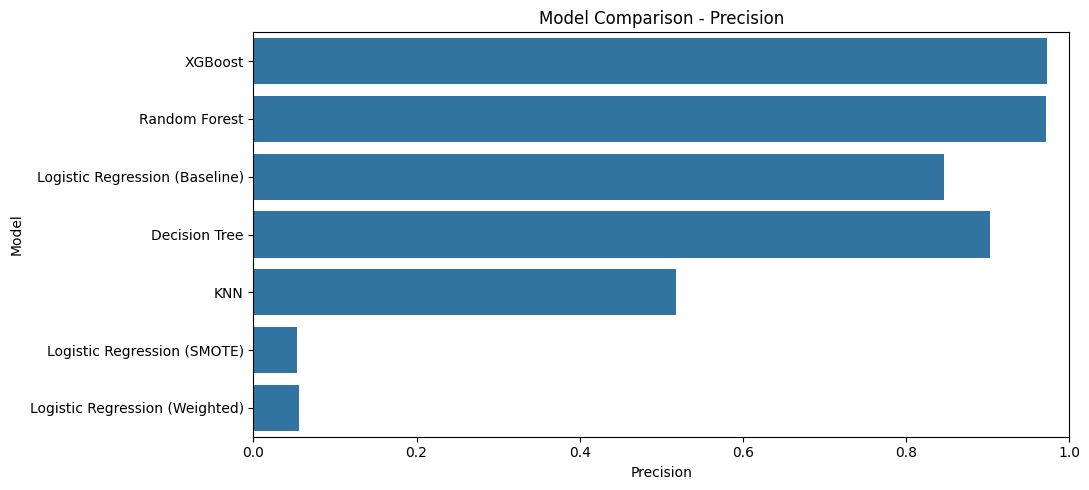

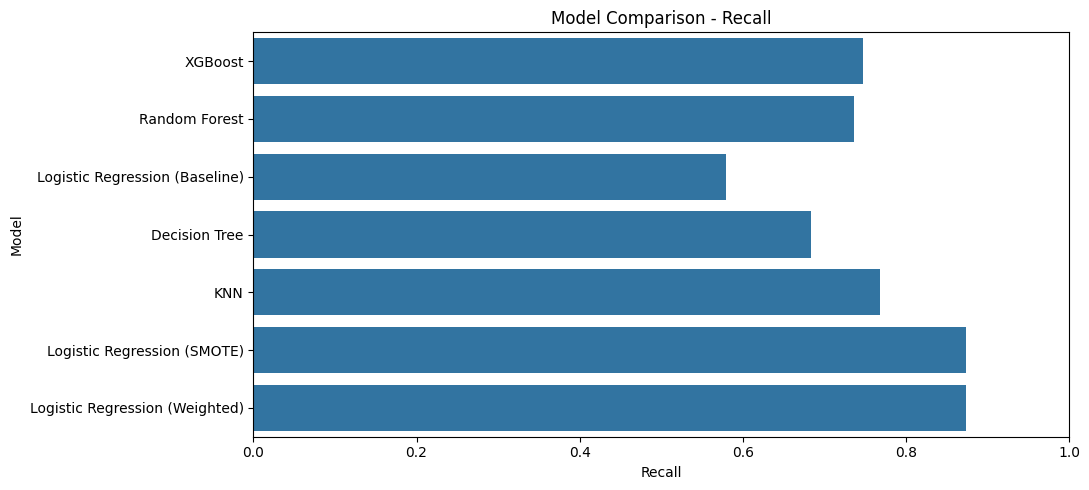

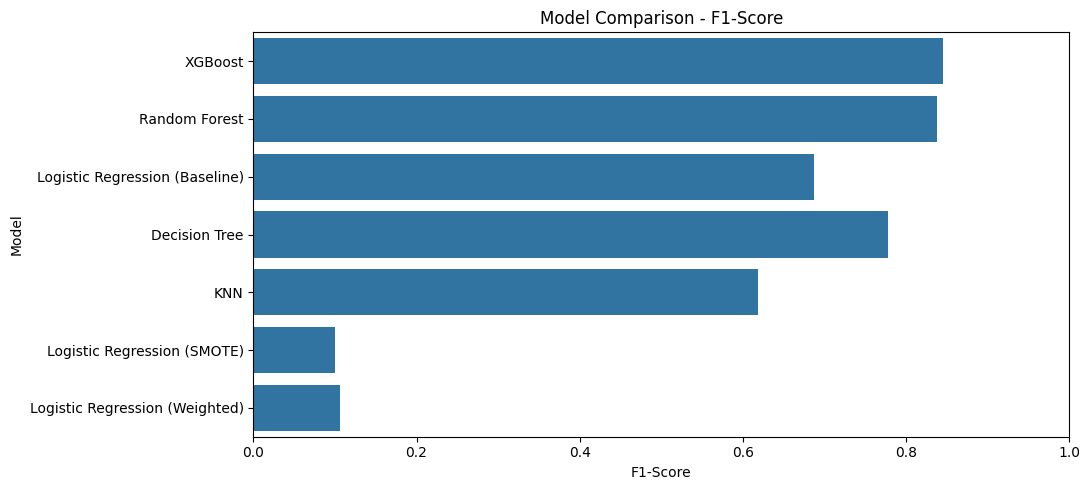

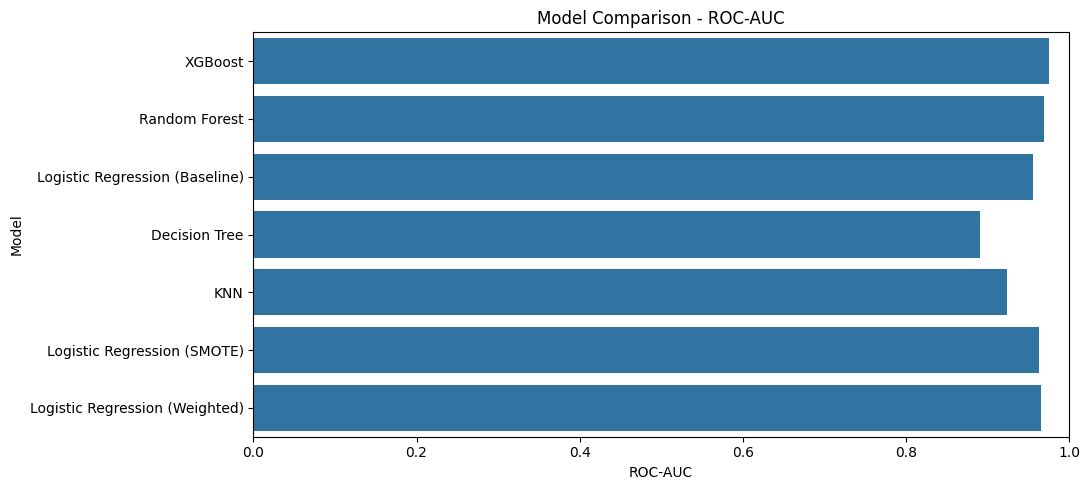

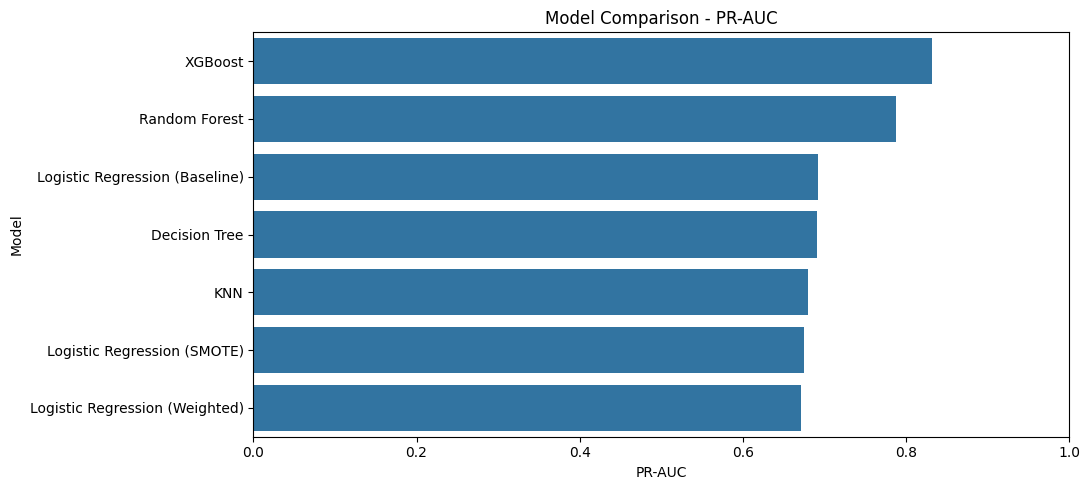

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics_to_plot = [
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "PR-AUC"
]

for metric in metrics_to_plot:

    plt.figure(figsize=(11, 5))

    sns.barplot(
        data=comparison_df,
        x=metric,
        y="Model"
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xlabel(metric)
    plt.ylabel("Model")
    plt.xlim(0, 1)
    plt.tight_layout()
    plt.show()

### 5.8.1 Model Comparison Analysis

Seven model experiments were evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and Average Precision (PR-AUC).

XGBoost achieved the strongest overall performance, with an F1-score of 0.8452, ROC-AUC of 0.9756, and PR-AUC of 0.8324.

Random Forest was the second-best overall model, achieving an F1-score of 0.8383 and PR-AUC of 0.7875.

KNN achieved the highest recall of 0.7684 among the evaluated experiments, but its precision was considerably lower at 0.5177.

Class-weighted and SMOTE-based Logistic Regression achieved higher recall than baseline Logistic Regression, but produced many false positives.

Based on these exploratory results, XGBoost is the leading candidate for further evaluation. However, final model selection will require validation on data that has not been used for model comparison or threshold selection.

# 6. Model Evaluation and Feature Analysis

This section compares model predictions using confusion matrices, ROC curves, and Precision-Recall curves. Feature-importance plots are also examined for the tree-based models.

The visualizations support model comparison, but feature importance is model-specific and should not be interpreted as evidence of causation.

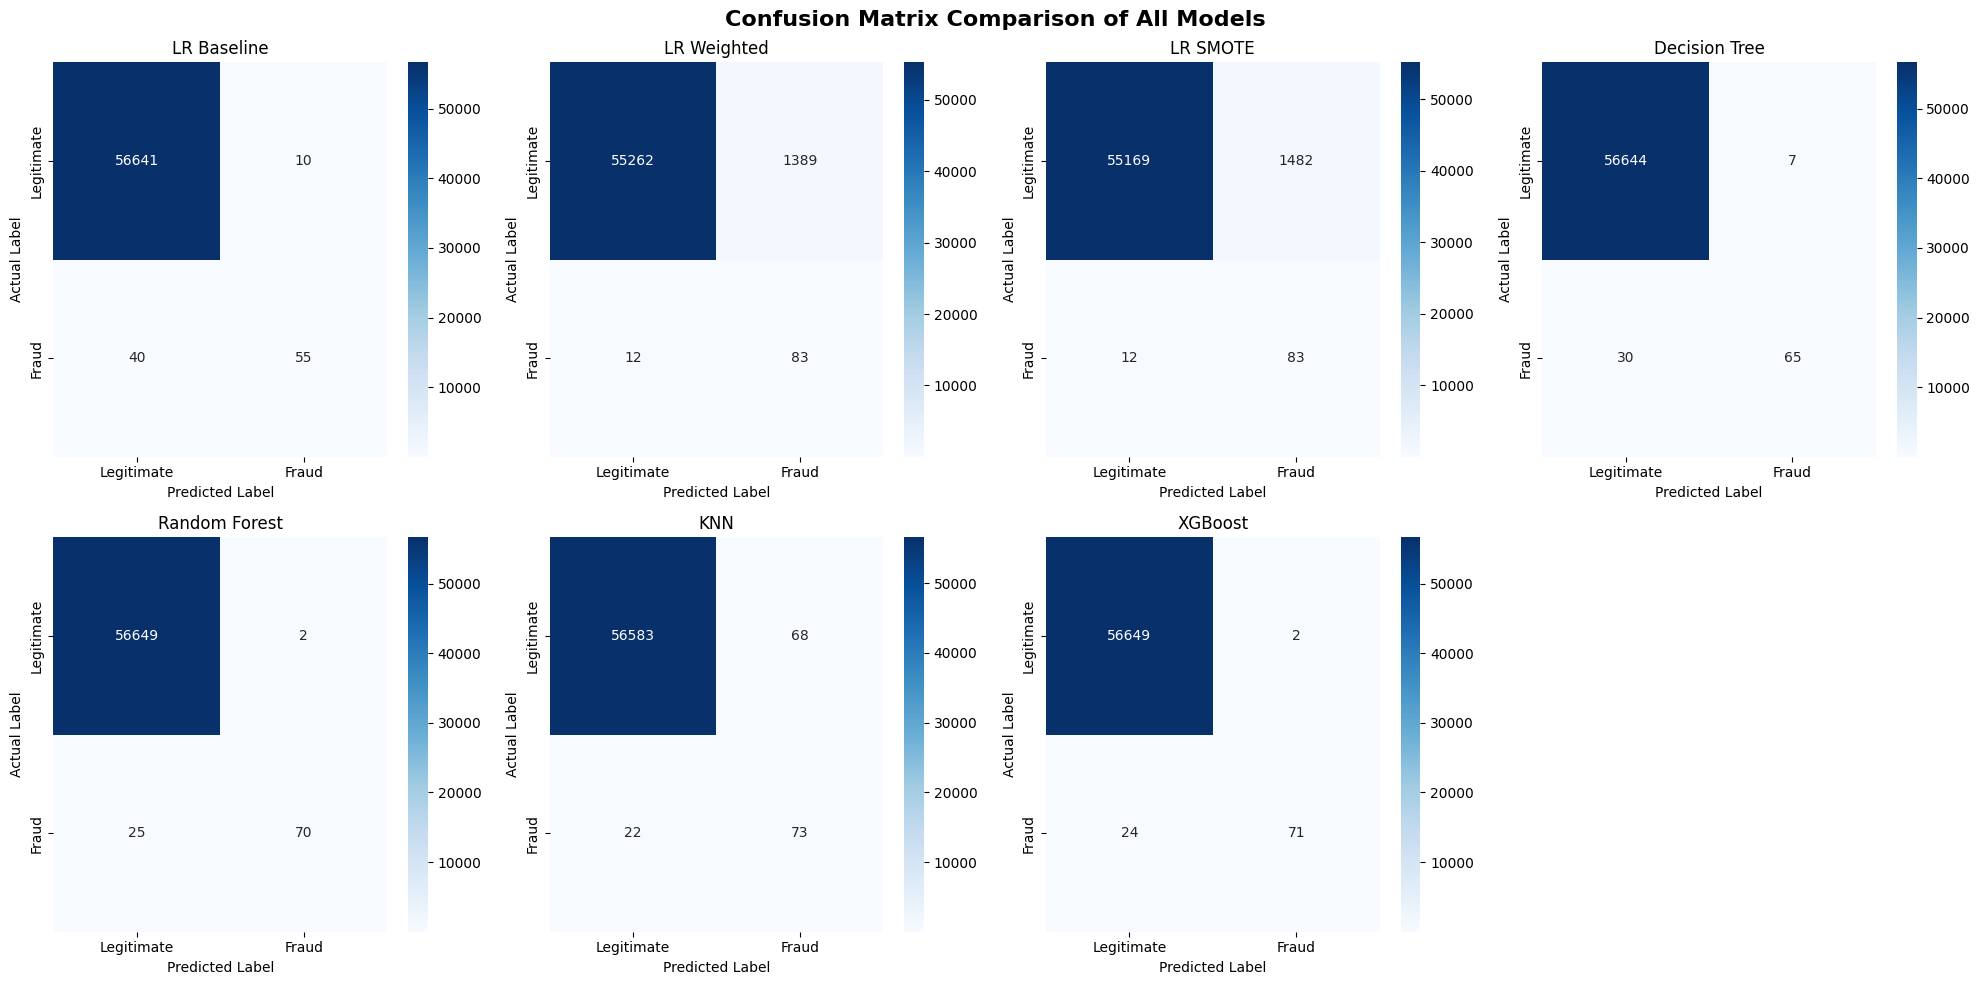

In [45]:
# ============================================================
# 6.1 CONFUSION MATRIX COMPARISON
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

models = {
    "LR Baseline": y_pred_baseline,
    "LR Weighted": y_pred_weighted,
    "LR SMOTE": y_pred_smote,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "KNN": y_pred_knn,
    "XGBoost": y_pred_xgb
}

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

axes = axes.flatten()

for i, (model_name, predictions) in enumerate(models.items()):

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Legitimate', 'Fraud'],
        yticklabels=['Legitimate', 'Fraud'],
        ax=axes[i]
    )

    axes[i].set_title(model_name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

# Remove the unused eighth subplot
fig.delaxes(axes[7])

plt.suptitle(
    "Confusion Matrix Comparison of All Models",
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.savefig(
    "/content/credit-card-fraud-detection/results/confusion_matrices/all_models_confusion_matrix.png",
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [46]:
import os

os.makedirs(
    "/content/credit-card-fraud-detection/results/confusion_matrices",
    exist_ok=True
)

plt.figure(figsize=(10, 5))

# Recreate the figure before saving if needed.
# Better: save the combined figure directly before plt.show().

<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

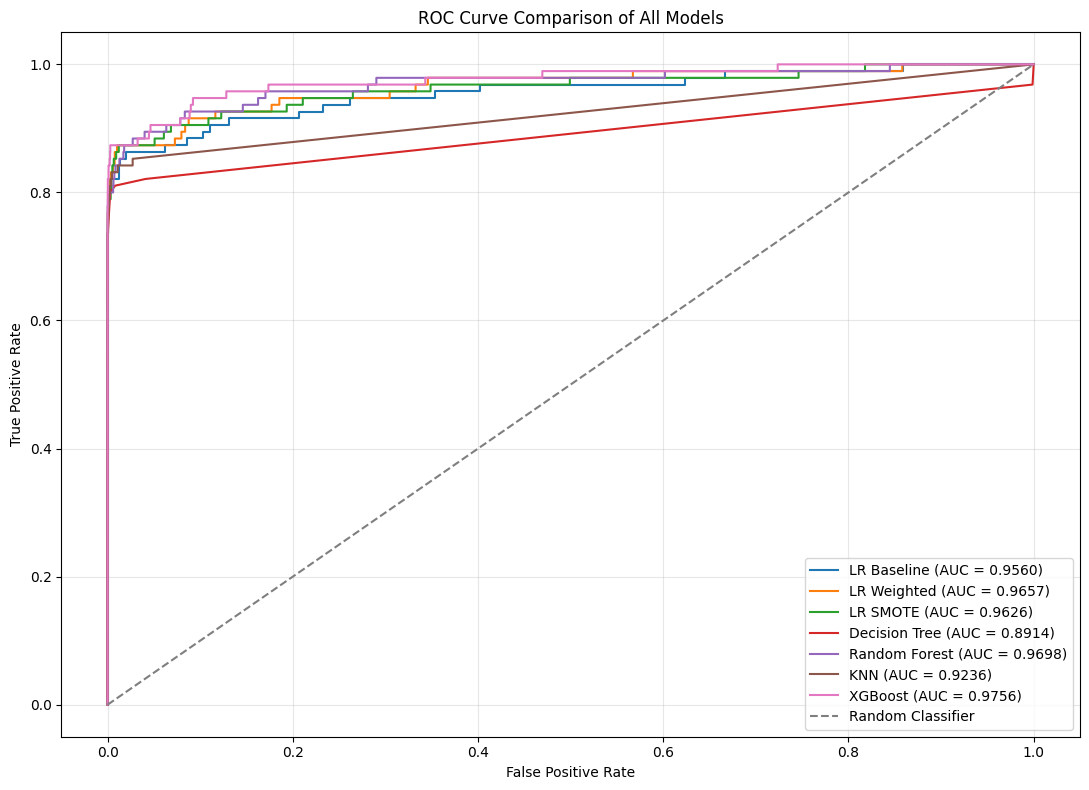

In [47]:
# ============================================================
# 6.2 ROC CURVE COMPARISON
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

model_probabilities = {
    "LR Baseline": y_prob_baseline,
    "LR Weighted": y_prob_weighted,
    "LR SMOTE": y_prob_smote,
    "Decision Tree": y_prob_dt,
    "Random Forest": y_prob_rf,
    "KNN": y_prob_knn,
    "XGBoost": y_prob_xgb
}

plt.figure(figsize=(11, 8))

for model_name, probabilities in model_probabilities.items():

    fpr, tpr, thresholds = roc_curve(y_test, probabilities)

    auc_score = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_score:.4f})"
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of All Models")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "/content/all_models_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

The ROC curve comparison shows that XGBoost achieved the highest ROC-AUC of 0.9756, followed by Random Forest with 0.9698. These results indicate that both ensemble models demonstrate strong class discrimination. Decision Tree achieved the lowest ROC-AUC of 0.8914 among the evaluated models. However, ROC-AUC alone is insufficient for evaluating performance on a severely imbalanced dataset, so Precision-Recall analysis is also necessary.

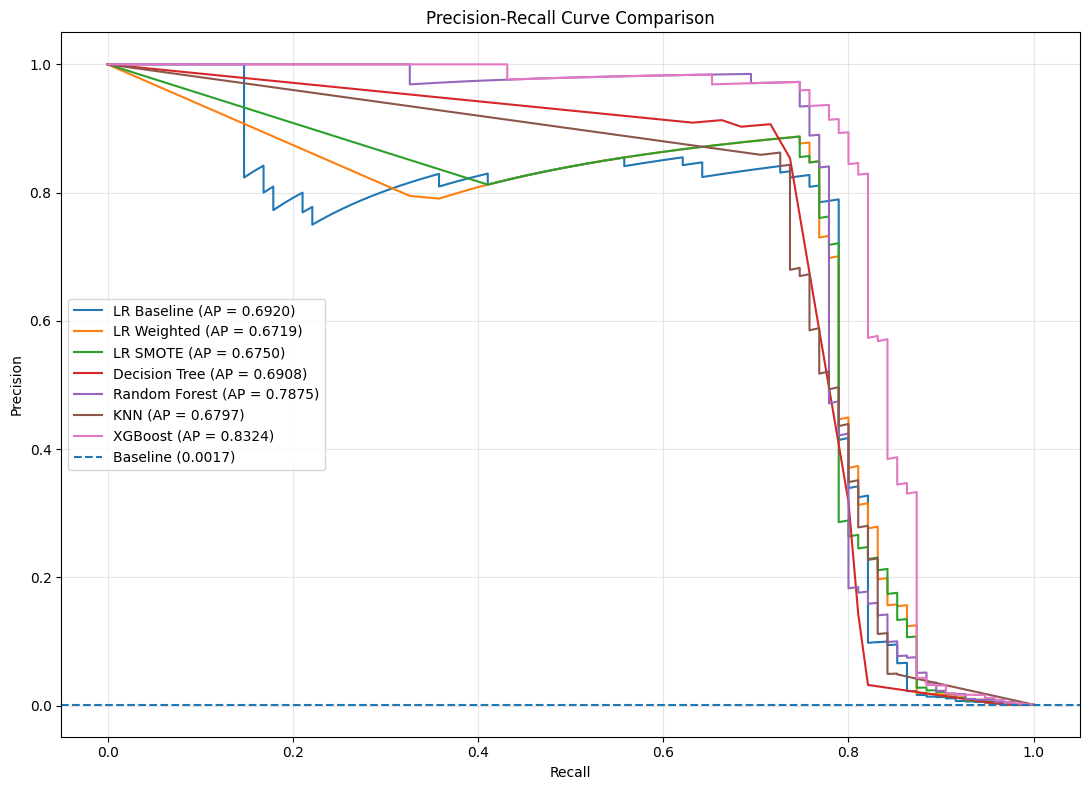

In [48]:
# ============================================================
# 6.3 PRECISION-RECALL CURVE COMPARISON
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

model_probabilities = {
    "LR Baseline": y_prob_baseline,
    "LR Weighted": y_prob_weighted,
    "LR SMOTE": y_prob_smote,
    "Decision Tree": y_prob_dt,
    "Random Forest": y_prob_rf,
    "KNN": y_prob_knn,
    "XGBoost": y_prob_xgb
}

plt.figure(figsize=(11, 8))

for model_name, probabilities in model_probabilities.items():

    precision, recall, thresholds = precision_recall_curve(
        y_test,
        probabilities
    )

    ap_score = average_precision_score(y_test, probabilities)

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (AP = {ap_score:.4f})"
    )

# Baseline represents the positive-class proportion
baseline = y_test.mean()

plt.axhline(
    y=baseline,
    linestyle='--',
    label=f'Baseline ({baseline:.4f})'
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")

plt.legend(loc="best")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/content/all_models_precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The Precision-Recall curve comparison indicates that XGBoost achieved the highest Average Precision score of 0.8324, followed by Random Forest with 0.7875. These ensemble models demonstrate better precision-recall performance than the other evaluated approaches. Since the dataset is highly imbalanced, Average Precision provides an important perspective on fraud detection performance. XGBoost is therefore the leading candidate based on the current exploratory results.

Top 15 Random Forest Features:


,Feature,Importance
17,V17,0.166251
14,V14,0.149858
12,V12,0.146880
10,V10,0.097459
16,V16,0.083125
11,V11,0.052031
9,V9,0.035551
18,V18,0.032196
7,V7,0.028351
4,V4,0.025389


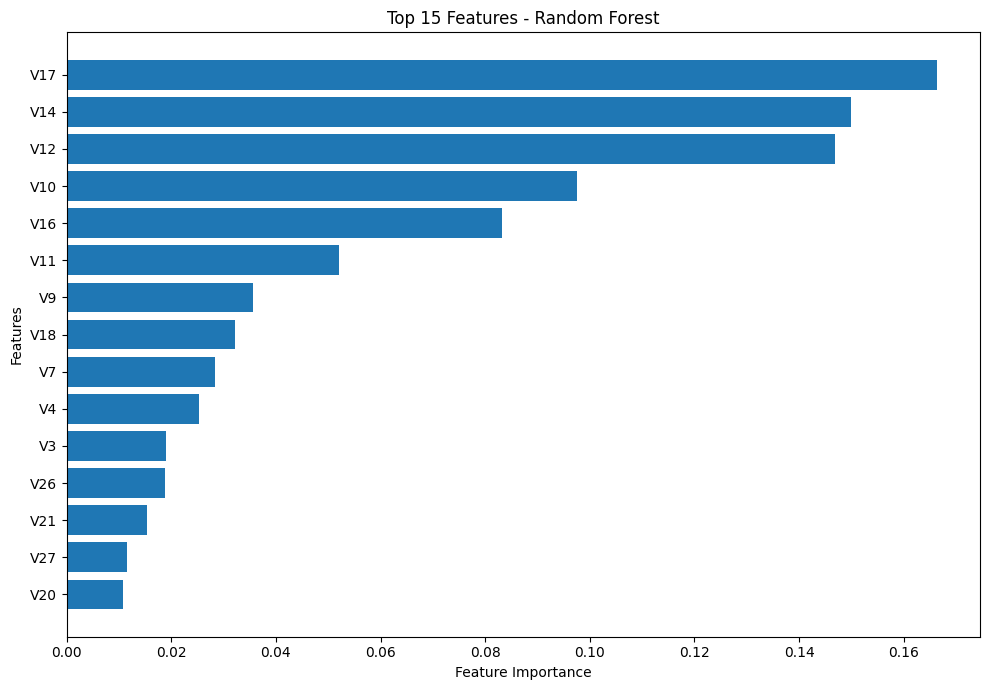

In [49]:
# ============================================================
# 6.4.1 RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_baseline.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Random Forest Features:")
display(rf_importance.head(15))

plt.figure(figsize=(10, 7))

plt.barh(
    rf_importance.head(15)["Feature"][::-1],
    rf_importance.head(15)["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Features - Random Forest")

plt.tight_layout()

plt.savefig(
    "/content/random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Top 15 XGBoost Features:


,Feature,Importance
14,V14,0.485887
10,V10,0.123208
12,V12,0.060792
4,V4,0.025108
17,V17,0.018136
3,V3,0.015045
8,V8,0.014908
5,V5,0.014116
26,V26,0.013775
16,V16,0.012769


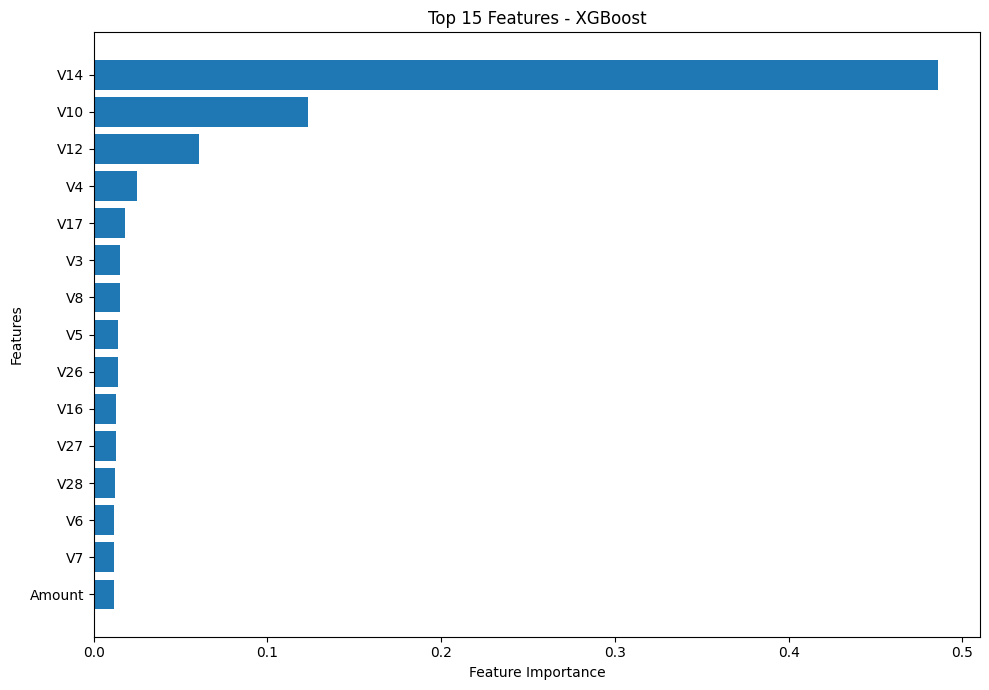

In [50]:
# ============================================================
# 6.4.2 XGBOOST FEATURE IMPORTANCE
# ============================================================

xgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 XGBoost Features:")
display(xgb_importance.head(15))

plt.figure(figsize=(10, 7))

plt.barh(
    xgb_importance.head(15)["Feature"][::-1],
    xgb_importance.head(15)["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Features - XGBoost")

plt.tight_layout()

plt.savefig(
    "/content/xgboost_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Feature importance analysis was performed using Random Forest and XGBoost to identify influential input variables. The analysis helps understand which features contribute most to the models' predictive decisions. Since V1–V28 are anonymized PCA-transformed features, their original real-world meanings are not directly available. Feature importance indicates model reliance rather than causal relationships

Feature importance analysis revealed that V17, V14, V12 and V10 were among the most influential features for both Random Forest and XGBoost. Random Forest distributed importance relatively broadly across multiple features, whereas XGBoost assigned a particularly high importance to V14. These findings are consistent with the earlier exploratory analysis. However, since the PCA-transformed features are anonymized, their original real-world interpretations are unavailable. Feature importance represents model-specific predictive contribution and does not establish causation.

# 7. Final Model Development and Threshold Optimization

To reduce the risk of selecting a model based on repeated use of the exploratory test set, a fresh stratified training-validation-test split is created. Candidate models are trained on the training partition and compared using validation data.

Classification thresholds are also investigated on the validation set. The final test partition is kept separate for the final evaluation.

In [51]:
# ============================================================
# 7.1 FRESH TRAIN-VALIDATION-TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=['Class'])
y = df_clean['Class']

# First separate the final test set
X_train_val, X_test_final, y_train_val, y_test_final = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Split the remaining data into training and validation
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=y_train_val
)

print("Training set:", X_train_final.shape)
print("Validation set:", X_val.shape)
print("Final test set:", X_test_final.shape)

print("\nFraud distribution:")

print("Training:")
print(y_train_final.value_counts())

print("\nValidation:")
print(y_val.value_counts())

print("\nFinal Test:")
print(y_test_final.value_counts())

Training set: (198608, 30)
Validation set: (42559, 30)
Final test set: (42559, 30)

Fraud distribution:
Training:
Class
0    198277
1       331
Name: count, dtype: int64

Validation:
Class
0    42488
1       71
Name: count, dtype: int64

Final Test:
Class
0    42488
1       71
Name: count, dtype: int64


In [52]:
# ============================================================
# 7.1 FEATURE SCALING FOR FINAL MODEL DEVELOPMENT
# ============================================================

from sklearn.preprocessing import StandardScaler
import pandas as pd

scaler_final = StandardScaler()

# Fit only on training data
X_train_final_scaled = scaler_final.fit_transform(X_train_final)

# Transform validation and final test data
X_val_scaled = scaler_final.transform(X_val)
X_test_final_scaled = scaler_final.transform(X_test_final)

# Convert arrays back into DataFrames
X_train_final_scaled = pd.DataFrame(
    X_train_final_scaled,
    columns=X_train_final.columns,
    index=X_train_final.index
)

X_val_scaled = pd.DataFrame(
    X_val_scaled,
    columns=X_val.columns,
    index=X_val.index
)

X_test_final_scaled = pd.DataFrame(
    X_test_final_scaled,
    columns=X_test_final.columns,
    index=X_test_final.index
)

print("Training:", X_train_final_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Final Test:", X_test_final_scaled.shape)

Training: (198608, 30)
Validation: (42559, 30)
Final Test: (42559, 30)


In [53]:
# ============================================================
# 7.2 SMOTE ON TRAINING DATA ONLY
# ============================================================

from imblearn.over_sampling import SMOTE

smote_final = SMOTE(random_state=42)

X_train_smote_final, y_train_smote_final = (
    smote_final.fit_resample(
        X_train_final_scaled,
        y_train_final
    )
)

print("Before SMOTE:")
print(y_train_final.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote_final.value_counts())

Before SMOTE:
Class
0    198277
1       331
Name: count, dtype: int64

After SMOTE:
Class
0    198277
1    198277
Name: count, dtype: int64


In [54]:
# ============================================================
# 7.3.1 TRAIN CANDIDATE MODELS
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# 1. Logistic Regression - Baseline
lr_final = LogisticRegression(
    max_iter=1000,
    random_state=42
)
lr_final.fit(X_train_final_scaled, y_train_final)

# 2. Logistic Regression - Class Weighted
lr_weighted_final = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)
lr_weighted_final.fit(X_train_final_scaled, y_train_final)

# 3. Logistic Regression - SMOTE
lr_smote_final = LogisticRegression(
    max_iter=1000,
    random_state=42
)
lr_smote_final.fit(X_train_smote_final, y_train_smote_final)

# 4. Random Forest
rf_final = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)
rf_final.fit(X_train_final, y_train_final)

# 5. Decision Tree
dt_final = DecisionTreeClassifier(
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)
dt_final.fit(X_train_final, y_train_final)

# 6. XGBoost
xgb_final = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1,
    scale_pos_weight=1,
    eval_metric="aucpr",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)
xgb_final.fit(X_train_final, y_train_final)

print("All six candidate models trained successfully.")

All six candidate models trained successfully.


In [55]:
# ============================================================
# 7.3.2 VALIDATION PREDICTIONS
# ============================================================

final_models = {
    "LR Baseline": lr_final,
    "LR Weighted": lr_weighted_final,
    "LR SMOTE": lr_smote_final,
    "Random Forest": rf_final,
    "Decision Tree": dt_final,
    "XGBoost": xgb_final
}

validation_probabilities = {}

for name, model in final_models.items():

    if name.startswith("LR"):
        probabilities = model.predict_proba(X_val_scaled)[:, 1]
    else:
        probabilities = model.predict_proba(X_val)[:, 1]

    validation_probabilities[name] = probabilities

print("Validation predictions generated for all models.")

Validation predictions generated for all models.


In [56]:
# ============================================================
# 7.3.3 VALIDATION PERFORMANCE COMPARISON
# ============================================================

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

validation_results = []

for name, probabilities in validation_probabilities.items():

    predictions = (probabilities >= 0.5).astype(int)

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-Score": f1_score(y_val, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "PR-AUC": average_precision_score(y_val, probabilities)
    })

validation_comparison = pd.DataFrame(validation_results)

validation_comparison = validation_comparison.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

display(validation_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,XGBoost,0.9997,0.9833,0.8310,0.9008,0.9808,0.8631
1,Random Forest,0.9996,0.9655,0.7887,0.8682,0.9764,0.8488
2,Decision Tree,0.9996,0.9206,0.8169,0.8657,0.9580,0.7935
3,LR Baseline,0.9992,0.8333,0.6338,0.7200,0.9834,0.7665
4,LR Weighted,0.9764,0.0611,0.9155,0.1145,0.9767,0.7217
5,LR SMOTE,0.9740,0.0549,0.9014,0.1036,0.9734,0.6978


In [57]:
# ============================================================
# 7.4 THRESHOLD OPTIMIZATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

candidate_models = [
    "XGBoost",
    "Random Forest",
    "Decision Tree"
]

threshold_results = []

for model_name in candidate_models:

    probabilities = validation_probabilities[model_name]

    for threshold in np.arange(0.01, 1.00, 0.01):

        predictions = (probabilities >= threshold).astype(int)

        precision = precision_score(
            y_val, predictions, zero_division=0
        )

        recall = recall_score(
            y_val, predictions, zero_division=0
        )

        f1 = f1_score(
            y_val, predictions, zero_division=0
        )

        tn, fp, fn, tp = confusion_matrix(
            y_val, predictions, labels=[0, 1]
        ).ravel()

        threshold_results.append({
            "Model": model_name,
            "Threshold": round(threshold, 2),
            "Precision": precision,
            "Recall": recall,
            "F1-Score": f1,
            "False Positives": fp,
            "False Negatives": fn,
            "True Positives": tp
        })

threshold_df = pd.DataFrame(threshold_results)

print("Threshold optimization completed.")

Threshold optimization completed.


In [58]:
# ============================================================
# 7.4.3 BEST THRESHOLDS
# ============================================================

best_f1_rows = []

for model_name in candidate_models:

    model_data = threshold_df[
        threshold_df["Model"] == model_name
    ]

    best_row = model_data.loc[
        model_data["F1-Score"].idxmax()
    ]

    best_f1_rows.append(best_row)

best_f1_comparison = pd.DataFrame(best_f1_rows)

print("Best F1 threshold for each model:")
display(best_f1_comparison.round(4))

Best F1 threshold for each model:


,Model,Threshold,Precision,Recall,F1-Score,False Positives,False Negatives,True Positives
30,XGBoost,0.31,0.9833,0.8310,0.9008,1,12,59
133,Random Forest,0.35,0.9355,0.8169,0.8722,4,13,58
258,Decision Tree,0.61,0.9508,0.8169,0.8788,3,13,58


In [59]:
# ============================================================
# 7.4.4 HIGH-RECALL THRESHOLD
# ============================================================

high_recall_rows = []

for model_name in candidate_models:

    model_data = threshold_df[
        (threshold_df["Model"] == model_name) &
        (threshold_df["Recall"] >= 0.90)
    ]

    if not model_data.empty:

        best_row = model_data.loc[
            model_data["Precision"].idxmax()
        ]

        high_recall_rows.append(best_row)

high_recall_comparison = pd.DataFrame(high_recall_rows)

print("Best precision while maintaining at least 90% recall:")

if not high_recall_comparison.empty:
    display(high_recall_comparison.round(4))
else:
    print("No candidate achieved 90% recall.")

Best precision while maintaining at least 90% recall:
No candidate achieved 90% recall.


Threshold optimization was performed using validation data to identify suitable classification thresholds. XGBoost achieved the highest F1-score of 0.9008 at a threshold of 0.31, with a precision of 0.9833 and recall of 0.8310. Decision Tree achieved an F1-score of 0.8788, while Random Forest achieved 0.8722. XGBoost therefore remains the leading candidate based on the selected F1-score objective.

In [61]:
# ============================================================
# 7.4.5 FAST HIGH-RECALL THRESHOLD SEARCH
# ============================================================

from sklearn.metrics import precision_recall_curve
import pandas as pd

high_recall_rows = []

for model_name in candidate_models:

    probabilities = validation_probabilities[model_name]

    precision, recall, thresholds = precision_recall_curve(
        y_val,
        probabilities
    )

    # Thresholds correspond to all precision/recall values
    # except the final precision and recall entries.
    valid_indices = [
        i for i, r in enumerate(recall[:-1])
        if r >= 0.90
    ]

    if valid_indices:

        # Select the eligible threshold with maximum precision
        best_idx = max(
            valid_indices,
            key=lambda i: precision[i]
        )

        threshold = thresholds[best_idx]

        predictions = (
            probabilities >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val,
            predictions,
            labels=[0, 1]
        ).ravel()

        high_recall_rows.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision[best_idx],
            "Recall": recall[best_idx],
            "F1-Score": f1_score(
                y_val, predictions, zero_division=0
            ),
            "False Positives": fp,
            "False Negatives": fn,
            "True Positives": tp
        })

extended_high_recall = pd.DataFrame(high_recall_rows)

if not extended_high_recall.empty:
    display(extended_high_recall.round(4))
else:
    print("No model achieved 90% recall.")

,Model,Threshold,Precision,Recall,F1-Score,False Positives,False Negatives,True Positives
0,XGBoost,0.0010,0.0687,0.9014,0.1276,868,7,64
1,Random Forest,0.0019,0.0740,0.9014,0.1368,801,7,64
2,Decision Tree,0.0012,0.0292,0.9014,0.0565,2131,7,64


High-recall threshold optimization was also performed to investigate the possibility of detecting at least 90% of fraudulent transactions. All three candidate models achieved a recall of 90.14%. However, this resulted in a substantial increase in false positives. XGBoost generated 868 false positives, Random Forest generated 801, and Decision Tree generated 2,131. Therefore, the maximum-F1 strategy was selected as the preferred candidate because it provided a more balanced trade-off between precision and recall.

# 8. Final Model Selection and Independent Test Evaluation

XGBoost is selected based on its validation performance. The training and validation partitions are then combined to fit the final model. The final test set is used only for the final performance assessment.

The selected threshold of **0.31** was determined during validation-based threshold optimization and is carried forward for final testing. It is not retuned using final test labels.

In [62]:
# ============================================================
# 8.1.1 COMBINE TRAINING AND VALIDATION DATA
# ============================================================

import pandas as pd

X_train_combined = pd.concat(
    [X_train_final, X_val],
    axis=0
)

y_train_combined = pd.concat(
    [y_train_final, y_val],
    axis=0
)

print("Combined training shape:", X_train_combined.shape)
print("\nCombined class distribution:")
print(y_train_combined.value_counts())

print("\nFinal test shape:", X_test_final.shape)

Combined training shape: (241167, 30)

Combined class distribution:
Class
0    240765
1       402
Name: count, dtype: int64

Final test shape: (42559, 30)


In [63]:
# ============================================================
# 8.1.2 TRAIN FINAL XGBOOST MODEL
# ============================================================

from xgboost import XGBClassifier

final_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1,
    scale_pos_weight=1,
    eval_metric="aucpr",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

final_model.fit(
    X_train_combined,
    y_train_combined
)

print("Final XGBoost model trained successfully.")

Final XGBoost model trained successfully.


In [64]:
# ============================================================
# 8.1.3 FINAL TEST PREDICTIONS
# ============================================================

import numpy as np

FINAL_THRESHOLD = 0.31

y_prob_final = final_model.predict_proba(
    X_test_final
)[:, 1]

y_pred_final = (
    y_prob_final >= FINAL_THRESHOLD
).astype(int)

print("Final predictions generated.")
print("Selected threshold:", FINAL_THRESHOLD)

Final predictions generated.
Selected threshold: 0.31


## 8.2 Final Test Results

The following cells report the final model's performance, confusion matrix, and classification report on the untouched final test partition.

In [65]:
# ============================================================
# 8.2.1 FINAL MODEL EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
final_accuracy = accuracy_score(y_test_final, y_pred_final)
final_precision = precision_score(y_test_final, y_pred_final)
final_recall = recall_score(y_test_final, y_pred_final)
final_f1 = f1_score(y_test_final, y_pred_final)

final_roc_auc = roc_auc_score(
    y_test_final, y_prob_final
)

final_pr_auc = average_precision_score(
    y_test_final, y_prob_final
)

# Display results
print("FINAL XGBOOST MODEL PERFORMANCE")
print("=" * 45)

print(f"Accuracy:  {final_accuracy:.4f}")
print(f"Precision: {final_precision:.4f}")
print(f"Recall:    {final_recall:.4f}")
print(f"F1-Score:  {final_f1:.4f}")
print(f"ROC-AUC:   {final_roc_auc:.4f}")
print(f"PR-AUC:    {final_pr_auc:.4f}")

FINAL XGBOOST MODEL PERFORMANCE
Accuracy:  0.9995
Precision: 0.9298
Recall:    0.7465
F1-Score:  0.8281
ROC-AUC:   0.9713
PR-AUC:    0.8304


Confusion Matrix:
[[42484     4]
 [   18    53]]


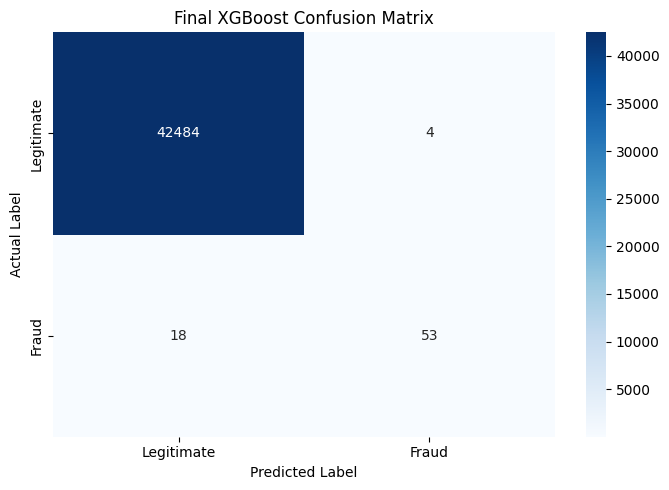

In [66]:
# ============================================================
# 8.2.2 FINAL CONFUSION MATRIX
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

cm_final = confusion_matrix(
    y_test_final,
    y_pred_final
)

print("Confusion Matrix:")
print(cm_final)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Final XGBoost Confusion Matrix")

plt.tight_layout()
plt.show()

In [67]:
# ============================================================
# 8.2.3 CLASSIFICATION REPORT
# ============================================================

print(
    classification_report(
        y_test_final,
        y_pred_final,
        target_names=["Legitimate", "Fraud"],
        digits=4
    )
)

              precision    recall  f1-score   support

  Legitimate     0.9996    0.9999    0.9997     42488
       Fraud     0.9298    0.7465    0.8281        71

    accuracy                         0.9995     42559
   macro avg     0.9647    0.8732    0.9139     42559
weighted avg     0.9995    0.9995    0.9995     42559



[[42484     4]
 [   18    53]]


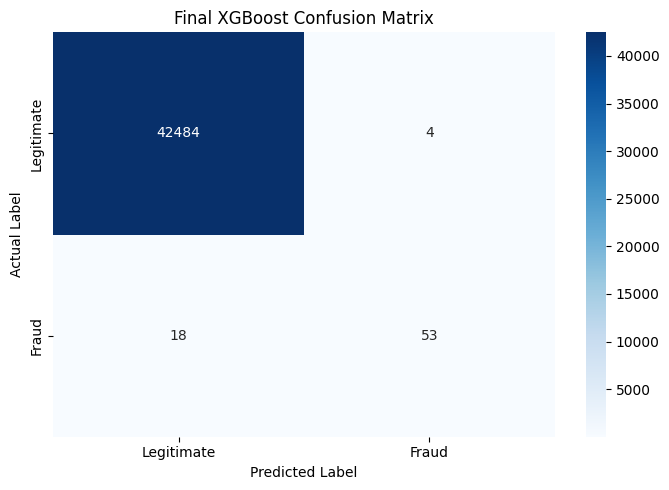

In [68]:
# Final confusion matrix
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_final = confusion_matrix(y_test_final, y_pred_final)

print(cm_final)

os.makedirs(
    "/content/credit-card-fraud-detection/results/confusion_matrices",
    exist_ok=True
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Final XGBoost Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "/content/credit-card-fraud-detection/results/confusion_matrices/final_xgboost_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The final XGBoost classifier was evaluated on an independent test dataset containing 42,559 transactions, including 71 fraudulent transactions. Using a classification threshold of 0.31, the model achieved 99.95% accuracy, 92.98% precision, 74.65% recall, and an F1-score of 82.81%. The ROC-AUC and Average Precision scores were 0.9713 and 0.8304, respectively.

The results demonstrate that the model can identify fraudulent transactions with high precision while maintaining a reasonable detection rate. However, 18 fraudulent transactions were missed in the final test set. Further improvements could focus on increasing fraud detection recall while controlling false positives.

## 9. Conclusion and Limitations

### Conclusion

The final XGBoost model, evaluated at a threshold of **0.31**, achieved:

| Metric | Final test result |
|---|---:|
| Accuracy | 0.9995 |
| Precision | 0.9298 |
| Recall | 0.7465 |
| F1-score | 0.8281 |
| ROC-AUC | 0.9713 |
| Average Precision (PR-AUC) | 0.8304 |

On the final test set, the confusion matrix was:

| | Predicted legitimate | Predicted fraud |
|---|---:|---:|
| Actual legitimate | 42,484 | 4 |
| Actual fraud | 18 | 53 |

The model correctly identified 53 of the 71 fraudulent transactions and missed 18. It produced 4 false-positive predictions. These results show a strong precision-recall balance on this test sample, while also showing that some fraud cases remain undetected.

### Limitations and considerations

- **Class imbalance:** Fraud cases are rare, so accuracy alone can give an overly optimistic impression of performance.
- **Anonymized features:** The original meanings of `V1`–`V28` are not available, limiting domain-level interpretation.
- **Threshold transfer:** The threshold was selected on validation data and then transferred to a model refitted on the combined training and validation data. Refitting can change predicted probability calibration, so threshold stability should be checked with additional validation or calibration before deployment.
- **Dataset scope:** This is an offline experiment on a historical dataset. It does not establish performance on current transactions or a live payment system.
- **Operational trade-off:** A different application may prefer higher recall even if that creates more false-positive alerts. The appropriate threshold depends on the costs of missed fraud and unnecessary investigations.
- **Further validation:** Performance should be checked on additional independent data before any real-world use.


